# Male-specific detection of insulin resistance from consumer wearable features

**Secondary analysis of the WEAR-ME cohort (Metwally et al.)**

| Part | Content |
|---|---|
| 1 | Setup and preprocessing: settings, governance, analysis plan, preprocessing, cohort, sample size, model toolkit |
| 2 | RQ1: which wearable feature matters most (men) |
| 3 | RQ2: do wearables improve detection (men) |
| 4 | Sensitivity analyses |
| 5 | Summary for the write-up and session info |

Inside each part, every step follows the same pattern: **Run** (computation), **Evaluate** (tables and figures directly
below it), and a short **Interpret** step at the end of the part. Each step opens with a *What / Inputs / Outputs* note.

**How to run**
1. Put `ir_prediction_data.pq`, `data.pq` and the WEAR-ME CSV subset in a folder called `data/` next to this notebook.
2. Install the requirements, select the project kernel, then *Run all*.
3. Tables go to `outputs/tables/` (CSV), figures to `outputs/figures/` (PNG, 300 dpi).

**Caching.** Every *Run* step saves its results to `outputs/cache/`. On later runs they are loaded instead of recomputed,
so you can change a table or figure and re-run in seconds. The cache is tied to the run settings and the data file, so a
fast test run never feeds a full run. If you change code inside a *Run* step, set `USE_CACHE = False` (or delete
`outputs/cache/`) to force recomputation.

**Runtime.** First full run: roughly 10-25 minutes on a multi-core laptop (about 35 minutes on one core).
`WEARME_FAST=1` gives a quick test run of a few minutes; fast-mode numbers are **not** for reporting.

**File names.** Every output file starts with the number of the section that creates it (for example
`2.1_rq1_forest_men.png` comes from section 2.1).

In [75]:
# Requirements (run once if needed):
# pip install pandas numpy scipy statsmodels scikit-learn xgboost interpret pyarrow matplotlib joblib

# Part 1: Setup and preprocessing

## 1.1 Settings

**What:** imports libraries and sets every configurable value in one place.  
**Inputs:** environment variables `WEARME_FAST`, `WEARME_DATA`, `WEARME_OUT` (all optional).  
**Outputs:** run settings, output folders, helper functions for saving tables and figures.

In [76]:
import os, time, hashlib, warnings, platform, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression, RidgeCV
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_curve
import joblib
from joblib import Parallel, delayed
import xgboost
from xgboost import XGBClassifier
import interpret
from interpret.glassbox import ExplainableBoostingClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})
T0 = time.time()

In [77]:
# ---------------- configuration ----------------
FAST_MODE = os.environ.get("WEARME_FAST", "0") == "1"   # True = quick test run, NOT for reporting
USE_CACHE = True                                        # False = recompute every Run step

DATA_DIR = Path(os.environ.get("WEARME_DATA", "data"))
OUT_DIR  = Path(os.environ.get("WEARME_OUT", "outputs"))
TAB_DIR, FIG_DIR = OUT_DIR / "tables", OUT_DIR / "figures"
TAB_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 20260922
N_SPLITS = 5
N_REPEATS           = 2   if FAST_MODE else 20    # primary model (penalised logistic regression)
N_REPEATS_SECONDARY = 1   if FAST_MODE else 10    # XGBoost and EBM: first 10 repeats of the SAME folds
N_BOOT              = 200 if FAST_MODE else 2000  # participant bootstrap for CIs
N_BOOT_RANK         = 50  if FAST_MODE else 1000  # bootstrap for RQ1 rank stability
N_SUBSAMPLE         = 5   if FAST_MODE else 100   # unused; kept because it is part of the cache key below
N_JOBS = -1                                         # parallel folds; -1 = all cores

IR_CUTOFF, IR_CUTOFF_ALT = 2.9, 2.5
MIN_DAUROC = 0.02          # pre-specified minimum meaningful improvement
ANTICIPATED_C = 0.70       # from the original study (wearables + demographics), for the sample-size check

def save_table(df, name, index=False):
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)
    return df

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def timer(msg):
    print(f"[{(time.time() - T0)/60:5.1f} min] {msg}")

print(f"FAST_MODE={FAST_MODE} | repeats primary={N_REPEATS}, secondary={N_REPEATS_SECONDARY}, "
      f"bootstrap={N_BOOT} | USE_CACHE={USE_CACHE} | outputs -> {OUT_DIR.resolve()}")

FAST_MODE=False | repeats primary=20, secondary=10, bootstrap=2000 | USE_CACHE=True | outputs -> /Users/sujanlimbu/604/wearme/outputs


## 1.2 Load files and governance checks

**What:** records exactly which files were analysed (SHA-256), checks the files agree with each other, confirms the leakage risk in the outcome, and sets up the result cache.  
**Inputs:** `ir_prediction_data.pq`, `data.pq`, WEAR-ME CSV subset.  
**Outputs:** `1.2_file_inventory.csv`; consistency checks (printed); cache folder keyed to settings and data.

In [78]:
def find_file(pattern):
    for d in [DATA_DIR, Path(".")]:
        hits = sorted(d.glob(pattern))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"'{pattern}' not found in {DATA_DIR.resolve()} or the current folder")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

F_IR, F_DATA, F_CSV = find_file("ir_prediction_data.pq"), find_file("data.pq"), find_file("*wear_me*cohort*.csv")
raw  = pd.read_parquet(F_IR)
full = pd.read_parquet(F_DATA)
csv  = pd.read_csv(F_CSV)

inventory = pd.DataFrame([
    {"file": p.name, "rows": d.shape[0], "columns": d.shape[1], "sha256": sha256(p)}
    for p, d in [(F_IR, raw), (F_DATA, full), (F_CSV, csv)]
])
save_table(inventory, "1.2_file_inventory")
display(inventory)

chk = raw.merge(csv, left_on="participant_id", right_on="participant ID", how="outer", indicator=True)
extra_in_data_pq = sorted(set(full.participant_id) - set(raw.participant_id))
consistency = pd.Series({
    "IDs in both ir_prediction_data.pq and CSV": int((chk["_merge"] == "both").sum()),
    "IDs only in one of them": int((chk["_merge"] != "both").sum()),
    "Max |RHR mean difference| (rounding only)": round((chk["RHR_FreeLiving_mean"] - chk["resting heart Rate (mean)"]).abs().max(), 3),
    "Max |HOMA-IR difference| (rounding only)": round((chk["homa_ir"] - chk["true homa-ir"]).abs().max(), 3),
    "Participants in data.pq but not in the paper cohort": len(extra_in_data_pq),
    "Correlation: HOMA-IR vs glucose x insulin / 405": round(np.corrcoef(raw["homa_ir"], raw["glucose"] * raw["insulin"] / 405)[0, 1], 6),
})
print(consistency.to_string())
print("\nDecision: analyse ir_prediction_data.pq (the paper cohort, n=1,165); take active zone minutes from the CSV "
      "(not present in the parquet files). Insulin is never a predictor and glucose only enters its own tier.")

# Result cache: tied to run settings and the data file, so fast and full runs never mix
CACHE_KEY = (f"{'fast' if FAST_MODE else 'full'}_r{N_REPEATS}-{N_REPEATS_SECONDARY}_b{N_BOOT}-{N_BOOT_RANK}"
             f"_s{N_SUBSAMPLE}_seed{SEED}_{inventory.loc[0, 'sha256'][:10]}")
CACHE_DIR = OUT_DIR / "cache" / CACHE_KEY
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def cached(name, compute):
    path = CACHE_DIR / f"{name}.joblib"
    if USE_CACHE and path.exists():
        print(f"Loaded from cache: {name}")
        return joblib.load(path)
    t = time.time()
    obj = compute()
    joblib.dump(obj, path, compress=3)
    print(f"Computed and cached: {name} ({(time.time() - t)/60:.1f} min)")
    return obj
print(f"\nCache folder: {CACHE_DIR}")

,file,rows,columns,sha256
0,ir_prediction_data.pq,1165,155,3e3e46df223b2dd9bac8732eb0c1bebcef63327fa45af9fbe16ae3fdcce6d43b
1,data.pq,1173,154,e1824aa7926ecb665ead2fbc1806df253a99e91d52741ef552bcd5a5a4ac3f56
2,insulin_resistance_prediction_paper_subset_wear_me_insulin_resistance_cohort...,1165,68,5755fbb88e78a4f5376c3658fcae37ea1c2e345c7ee8eaeacec8081a969230be


IDs in both ir_prediction_data.pq and CSV              1165.000000
IDs only in one of them                                   0.000000
Max |RHR mean difference| (rounding only)                 0.050000
Max |HOMA-IR difference| (rounding only)                  0.050000
Participants in data.pq but not in the paper cohort       8.000000
Correlation: HOMA-IR vs glucose x insulin / 405           0.999999

Decision: analyse ir_prediction_data.pq (the paper cohort, n=1,165); take active zone minutes from the CSV (not present in the parquet files). Insulin is never a predictor and glucose only enters its own tier.

Cache folder: outputs/cache/full_r20-10_b2000-1000_s100_seed20260922_3e3e46df22


## 1.3 Analysis plan

**Design.** Secondary, cross-sectional analysis. Population: men without diabetes.

**Outcome.** Primary: insulin resistance, HOMA-IR ≥ 2.9. Secondary: continuous log HOMA-IR.

**Research questions**
- **RQ1**: In men, which wearable feature is most strongly associated with insulin resistance independent of age and BMI, and which adds most to detection?
- **RQ2**: Does adding wearable features improve detection meaningfully (ΔAUROC ≥ 0.02) and significantly, over (a) age + BMI and (b) a routine blood panel?

**Data.** Analysis file `ir_prediction_data.pq` (n = 1,165), with active zone minutes merged from the CSV by participant ID.

**Features.** Five wearable means: resting heart rate, HRV, daily steps, active zone minutes (AZM), sleep duration
(HRV, steps and AZM log-transformed). Base: age, BMI. Blood tier: triglycerides (log), HDL, HbA1c. Glucose tier: fasting glucose.

**Models.** Penalised (ridge) logistic regression = primary; shallow XGBoost = secondary; Explainable Boosting Machine (EBM) = pre-specified exploratory.
Repeated stratified 5-fold CV (20 repeats), nested inner 5-fold tuning, all preprocessing inside folds, identical folds for every tier.

**Significance test for RQ2.** Following supervisor review, the significance test for RQ2 is a likelihood-ratio test of the wearable block (Section 3.6), the recommended test for nested models. ΔAUROC is reported as an effect size with its 95% CI and is not tested separately.

## 1.4 Preprocessing

**What:** builds the analysis dataset: merges AZM, recodes missing-value codes, derives medication flags, applies log transforms, and defines every outcome.  
**Inputs:** raw parquet (`raw`) and CSV (`csv`).  
**Outputs:** analysis dataframe `df`; `1.4_preprocessing_log.csv` listing each step and how many records it affected.

In [79]:
ETH_MAP = {"White / Caucasian": "White", "Hispanic": "Hispanic", "African-American": "Black",
           "Asian - Indian": "Asian", "Asian - Eastern": "Asian"}
DM_TYPES = ["Type 2 diabetes", "Type 1 diabetes", "Latent autoimmune", "Other"]

azm = csv[["participant ID", "active zone minutes weekly (mean)", "active zone minutes weekly (std)"]].rename(
    columns={"participant ID": "participant_id", "active zone minutes weekly (mean)": "azm",
             "active zone minutes weekly (std)": "azm_sd"})
r = raw.merge(azm, on="participant_id", how="left")
meds, dmeds = r["medications"].fillna(""), r["diabetes_medications"].fillna("")

df = pd.DataFrame({
    "id": r["participant_id"], "sex": r["sex"],
    "age": r["age"], "bmi": r["bmi"], "waist": r["waist_circumference"],
    "sbp": r["systolic_bp"], "dbp": r["diastolic_bp"],
    "rhr": r["RHR_FreeLiving_mean"], "hrv": r["HRV_FreeLiving_mean"], "steps": r["STEPS_Daily_mean"],
    "azm": r["azm"], "sleep": r["SLEEP_Duration_mean"],
    "rhr_sd": r["RHR_FreeLiving_std"], "hrv_sd": r["HRV_FreeLiving_std"], "steps_sd": r["STEPS_Daily_std"],
    "azm_sd": r["azm_sd"], "sleep_sd": r["SLEEP_Duration_std"],
    "tg": r["triglycerides"], "hdl": r["hdl"], "hba1c": r["hba1c"], "glucose": r["glucose"],
    "insulin": r["insulin"], "homa": r["homa_ir"], "testosterone": r["total testosterone"],
    "smoker": r["smoker"].map({"Yes": 1, "No": 0}),
    "eth": r["ethnicity_original"].map(ETH_MAP).fillna("Other/unknown"),
    "dm_self": r["diabetes_type"].isin(DM_TYPES).astype(int),
    "glucose_med": (meds.str.contains("Insulin|Metformin or other oral") |
                    dmeds.str.contains("Insulin|Metformin|Other oral")).astype(int),
    "bp_med": meds.str.contains("Blood pressure medications").astype(int),
    "hr_med": meds.str.contains("Beta blockers|Heart medications").astype(int),
})

# Cleaning: HRV = -1 is a missing-value code
hrv_code = r["HRV_FreeLiving_mean"].eq(-1)
df.loc[hrv_code, ["hrv", "hrv_sd"]] = np.nan

# Outcomes
df["ir"] = (df["homa"] >= IR_CUTOFF).astype(int)
df["ir25"] = (df["homa"] >= IR_CUTOFF_ALT).astype(int)
df["log_homa"] = np.log(df["homa"])
df["lab_dm"] = ((df["hba1c"] >= 6.5) | (df["glucose"] >= 126)).astype(int)

# Transformations (deterministic, so no leakage)
for c in ["hrv", "steps", "azm", "hrv_sd", "steps_sd", "azm_sd"]:
    df[c + "_l"] = np.log1p(df[c])
df["tg_l"] = np.log(df["tg"])
df["testo_l"] = np.log(df["testosterone"])
for e in ["Hispanic", "Black", "Asian", "Other/unknown"]:
    df["eth_" + e.split("/")[0]] = df["eth"].eq(e).astype(int)

prep_log = pd.DataFrame([
    {"Step": "Active zone minutes merged from the CSV by participant ID", "Records affected": int(r["azm"].notna().sum()),
     "Note": "AZM is not in the parquet files"},
    {"Step": "HRV value -1 recoded as missing (mean and SD)", "Records affected": int(hrv_code.sum()),
     "Note": "-1 is a missing-value code"},
    {"Step": "Glucose-lowering medication flag (insulin, metformin, other oral drugs)", "Records affected": int(df["glucose_med"].sum()),
     "Note": "from medication lists; used for exclusion"},
    {"Step": "Blood pressure medication flag", "Records affected": int(df["bp_med"].sum()),
     "Note": "descriptive only"},
    {"Step": "Beta-blocker / heart medication flag", "Records affected": int(df["hr_med"].sum()),
     "Note": "used in sensitivity S8"},
    {"Step": "Ethnicity grouped (White, Hispanic, Black, Asian, Other/unknown)", "Records affected": len(df),
     "Note": "used in sensitivity S9"},
    {"Step": "Log transforms: HRV, steps, AZM (log1p, means and SDs); triglycerides, testosterone (log)", "Records affected": len(df),
     "Note": "reduces skew; deterministic, so no leakage"},
    {"Step": "Primary outcome: HOMA-IR ≥ 2.9", "Records affected": int(df["ir"].sum()), "Note": "cases, all participants"},
    {"Step": "Alternative outcome: HOMA-IR ≥ 2.5", "Records affected": int(df["ir25"].sum()), "Note": "sensitivity S2"},
    {"Step": "Secondary outcome: log HOMA-IR", "Records affected": int(df["log_homa"].notna().sum()), "Note": "sensitivity S1"},
])
save_table(prep_log, "1.4_preprocessing_log")
print("Analysis dataframe:", df.shape)
prep_log

Analysis dataframe: (1165, 46)


,Step,Records affected,Note
0,Active zone minutes merged from the CSV by participant ID,1162,AZM is not in the parquet files
1,HRV value -1 recoded as missing (mean and SD),2,-1 is a missing-value code
2,"Glucose-lowering medication flag (insulin, metformin, other oral drugs)",89,from medication lists; used for exclusion
3,Blood pressure medication flag,248,descriptive only
4,Beta-blocker / heart medication flag,67,used in sensitivity S8
5,"Ethnicity grouped (White, Hispanic, Black, Asian, Other/unknown)",1165,used in sensitivity S9
6,"Log transforms: HRV, steps, AZM (log1p, means and SDs); triglycerides, testo...",1165,"reduces skew; deterministic, so no leakage"
7,Primary outcome: HOMA-IR ≥ 2.9,303,"cases, all participants"
8,Alternative outcome: HOMA-IR ≥ 2.5,388,sensitivity S2
9,Secondary outcome: log HOMA-IR,1165,sensitivity S1


### Feature sets and model tiers

**What:** defines the wearable features, covariates and the six nested feature tiers used throughout.  
**Inputs:** column names in `df`.  
**Outputs:** `WEAR`, `BASE`, `BLOOD`, `GLU`, `TIERS` (M0 to M5), `CONTRASTS`, `DOMAINS`, labels.

In [80]:
WEAR = ["rhr", "hrv_l", "steps_l", "azm_l", "sleep"]
WEAR_RAW = ["rhr", "hrv", "steps", "azm", "sleep"]
SDS = ["rhr_sd", "hrv_sd_l", "steps_sd_l", "azm_sd_l", "sleep_sd"]
LABEL = {"rhr": "Resting heart rate", "hrv_l": "HRV", "steps_l": "Daily steps", "azm_l": "Active zone minutes",
         "sleep": "Sleep duration", "hrv": "HRV", "steps": "Daily steps", "azm": "Active zone minutes"}
UNITS = {"rhr": "bpm", "hrv": "ms", "steps": "steps/day", "azm": "min/week", "sleep": "min/night"}
BASE, BLOOD, GLU = ["age", "bmi"], ["tg_l", "hdl", "hba1c"], ["glucose"]
DOMAINS = {"Cardiac (RHR + HRV)": ["rhr", "hrv_l"], "Activity (steps + AZM)": ["steps_l", "azm_l"], "Sleep": ["sleep"]}

def tiers(base=BASE):
    return {"M0": base, "M1": base + WEAR, "M2": base + BLOOD, "M3": base + BLOOD + WEAR,
            "M4": base + BLOOD + GLU, "M5": base + BLOOD + GLU + WEAR}
TIERS = tiers()
CONTRASTS = [("M1", "M0"), ("M3", "M2"), ("M5", "M4")]
TIER_DESC = {"M0": "Age + BMI", "M1": "M0 + wearables", "M2": "M0 + TG, HDL, HbA1c", "M3": "M2 + wearables",
             "M4": "M2 + fasting glucose", "M5": "M4 + wearables"}
pd.DataFrame({"Tier": list(TIERS), "Description": [TIER_DESC[t] for t in TIERS],
              "Features": [", ".join(f) for f in TIERS.values()]})

,Tier,Description,Features
0,M0,Age + BMI,"age, bmi"
1,M1,M0 + wearables,"age, bmi, rhr, hrv_l, steps_l, azm_l, sleep"
2,M2,"M0 + TG, HDL, HbA1c","age, bmi, tg_l, hdl, hba1c"
3,M3,M2 + wearables,"age, bmi, tg_l, hdl, hba1c, rhr, hrv_l, steps_l, azm_l, sleep"
4,M4,M2 + fasting glucose,"age, bmi, tg_l, hdl, hba1c, glucose"
5,M5,M4 + wearables,"age, bmi, tg_l, hdl, hba1c, glucose, rhr, hrv_l, steps_l, azm_l, sleep"


## 1.5 Cohort

### Cohort flow

**What:** applies the exclusion rules step by step to the men in the cohort.  
**Inputs:** `df`.  
**Outputs:** analytic sample `men`; `1.5_cohort_flow.csv`.

In [81]:
def flow(d):
    steps = [("Men in the cohort", d)]
    d = d[d["dm_self"] == 0];      steps.append(("After excluding self-reported diabetes", d))
    d = d[d["glucose_med"] == 0];  steps.append(("After excluding insulin / oral glucose-lowering drugs", d))
    d = d[d["lab_dm"] == 0];       steps.append(("After excluding HbA1c ≥ 6.5% or glucose ≥ 126 mg/dL", d))
    return steps, d

flow_m, men = flow(df[df["sex"] == "Male"])
men = men.reset_index(drop=True)
flow_tab = pd.DataFrame([{"Step": lab, "n": len(d), "IR (HOMA-IR ≥ 2.9)": int(d["ir"].sum())} for lab, d in flow_m])
flow_tab.loc[len(flow_tab)] = {"Step": "Analytic prevalence of IR", "n": "", "IR (HOMA-IR ≥ 2.9)": f"{men['ir'].mean():.1%}"}
print(f"WEAR-ME cohort: {len(df)} participants, of whom {int((df.sex == 'Male').sum())} men")
save_table(flow_tab, "1.5_cohort_flow")
flow_tab

WEAR-ME cohort: 1165 participants, of whom 505 men


,Step,n,IR (HOMA-IR ≥ 2.9)
0,Men in the cohort,505,137
1,After excluding self-reported diabetes,479,119
2,After excluding insulin / oral glucose-lowering drugs,469,112
3,After excluding HbA1c ≥ 6.5% or glucose ≥ 126 mg/dL,464,108
4,Analytic prevalence of IR,,23.3%


### Table 1

**What:** describes the analytic sample by insulin-resistance status.  
**Inputs:** `men`.  
**Outputs:** `1.5_table1.csv` (median [IQR] or n (%); no p-values, following STROBE).

In [82]:
CONT = [("age", "Age, years"), ("bmi", "BMI, kg/m²"), ("waist", "Waist, cm"), ("sbp", "Systolic BP, mmHg"),
        ("homa", "HOMA-IR"), ("glucose", "Fasting glucose, mg/dL"), ("insulin", "Insulin, µU/mL"),
        ("hba1c", "HbA1c, %"), ("tg", "Triglycerides, mg/dL"), ("hdl", "HDL, mg/dL"),
        ("testosterone", "Total testosterone, ng/dL"),
        ("rhr", "Resting heart rate, bpm"), ("hrv", "HRV, ms"), ("steps", "Daily steps"),
        ("azm", "Active zone minutes, per week"), ("sleep", "Sleep duration, min")]
CAT = [("smoker", 1, "Current smoker"), ("bp_med", 1, "Blood pressure medication"),
       ("hr_med", 1, "Beta-blocker / heart medication")]

def t1_col(d):
    out = {"N": f"{len(d)}"}
    for c, lab in CONT:
        s = d[c].dropna()
        out[lab] = f"{s.median():.1f} [{s.quantile(.25):.1f}, {s.quantile(.75):.1f}]" if len(s) else "-"
    for c, v, lab in CAT:
        s = d[c].dropna()
        out[lab] = f"{int((s == v).sum())} ({(s == v).mean():.1%})" if len(s) else "-"
    for e in ["White", "Hispanic", "Black", "Asian", "Other/unknown"]:
        out[f"Ethnicity: {e}"] = f"{int(d['eth'].eq(e).sum())} ({d['eth'].eq(e).mean():.1%})"
    return pd.Series(out)

table1 = pd.concat({
    "Men, all": t1_col(men), "Men, not IR": t1_col(men[men.ir == 0]), "Men, IR": t1_col(men[men.ir == 1]),
}, axis=1)
save_table(table1.reset_index().rename(columns={"index": "Characteristic"}), "1.5_table1")
table1

,"Men, all","Men, not IR","Men, IR"
N,464,356,108
"Age, years","44.0 [36.0, 57.0]","43.0 [36.0, 55.0]","47.5 [38.8, 59.0]"
"BMI, kg/m²","26.7 [24.3, 30.6]","26.0 [23.7, 29.2]","30.3 [27.4, 34.8]"
"Waist, cm","88.9 [83.8, 99.1]","87.0 [81.3, 96.5]","97.8 [91.4, 106.7]"
"Systolic BP, mmHg","122.0 [117.0, 130.0]","120.0 [116.0, 128.8]","127.5 [120.0, 133.8]"
HOMA-IR,"1.8 [1.1, 2.8]","1.4 [0.9, 2.0]","4.0 [3.3, 5.4]"
"Fasting glucose, mg/dL","90.0 [86.0, 97.0]","89.0 [85.0, 94.0]","97.5 [90.8, 103.0]"
"Insulin, µU/mL","7.8 [5.1, 12.2]","6.3 [4.4, 9.0]","16.8 [13.8, 21.8]"
"HbA1c, %","5.4 [5.2, 5.6]","5.4 [5.2, 5.6]","5.5 [5.3, 5.7]"
"Triglycerides, mg/dL","90.0 [67.0, 131.0]","85.0 [63.0, 118.0]","128.5 [87.0, 182.5]"


### Missing data and feature correlations

**What:** summarises missing values in the men's sample and correlations among the wearable features.  
**Inputs:** `men`.  
**Outputs:** `1.5_missingness_men.csv`, `1.5_wearable_correlations_men.csv` and heatmap.

Model features with any missing values are median-imputed INSIDE each training fold.


,age,bmi,rhr,hrv,steps,azm,sleep,hdl,hba1c,tg,glucose,testosterone,waist,sbp,smoker
missing n,0.0,0.0,0.0,4.0,0.0,2.0,0.0,0.0,2.0,0.0,0.0,1.0,56.0,172.0,0.0
missing %,0.0,0.0,0.0,0.9,0.0,0.4,0.0,0.0,0.4,0.0,0.0,0.2,12.1,37.1,0.0


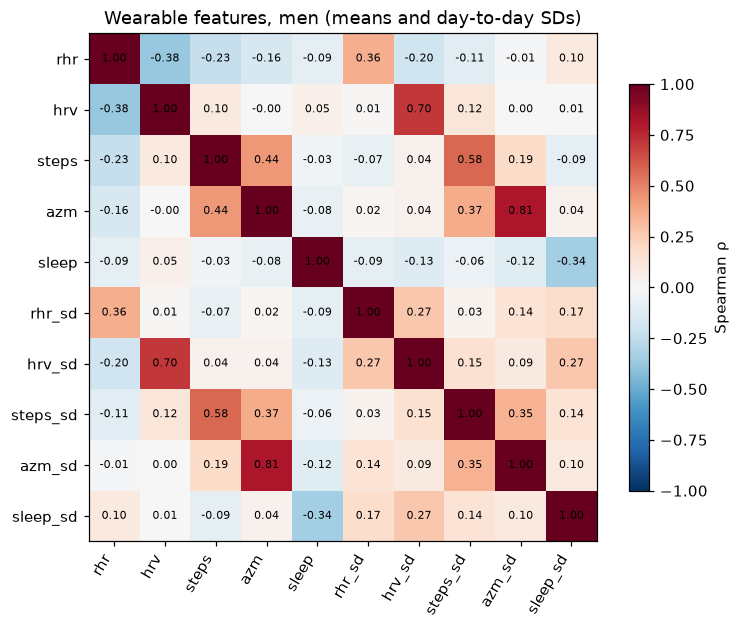

,index,rhr,hrv,steps,azm,sleep,rhr_sd,hrv_sd,steps_sd,azm_sd,sleep_sd
0,rhr,1.000,-0.380,-0.230,-0.161,-0.094,0.361,-0.200,-0.109,-0.012,0.100
1,hrv,-0.380,1.000,0.101,-0.004,0.051,0.014,0.703,0.120,0.003,0.006
2,steps,-0.230,0.101,1.000,0.436,-0.032,-0.073,0.040,0.578,0.187,-0.089
3,azm,-0.161,-0.004,0.436,1.000,-0.076,0.016,0.042,0.371,0.811,0.044
4,sleep,-0.094,0.051,-0.032,-0.076,1.000,-0.094,-0.125,-0.060,-0.122,-0.338
5,rhr_sd,0.361,0.014,-0.073,0.016,-0.094,1.000,0.267,0.033,0.136,0.172
6,hrv_sd,-0.200,0.703,0.040,0.042,-0.125,0.267,1.000,0.153,0.092,0.267
7,steps_sd,-0.109,0.120,0.578,0.371,-0.060,0.033,0.153,1.000,0.346,0.138
8,azm_sd,-0.012,0.003,0.187,0.811,-0.122,0.136,0.092,0.346,1.000,0.101
9,sleep_sd,0.100,0.006,-0.089,0.044,-0.338,0.172,0.267,0.138,0.101,1.000


In [83]:
MISS_VARS = BASE + WEAR_RAW + BLOOD[1:] + ["tg", "glucose", "testosterone", "waist", "sbp", "smoker"]
miss = pd.DataFrame({"missing n": men[MISS_VARS].isna().sum(), "missing %": (men[MISS_VARS].isna().mean() * 100).round(1)})
save_table(miss.reset_index().rename(columns={"index": "variable"}), "1.5_missingness_men")
print("Model features with any missing values are median-imputed INSIDE each training fold.")
display(miss.T)

corr_vars = WEAR_RAW + ["rhr_sd", "hrv_sd", "steps_sd", "azm_sd", "sleep_sd"]
cm = men[corr_vars].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_vars))); ax.set_xticklabels(corr_vars, rotation=60, ha="right")
ax.set_yticks(range(len(corr_vars))); ax.set_yticklabels(corr_vars)
for i in range(len(corr_vars)):
    for j in range(len(corr_vars)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Wearable features, men (means and day-to-day SDs)")
save_fig(fig, "1.5_wearable_correlations_men"); plt.show()
save_table(cm.round(3).reset_index(), "1.5_wearable_correlations_men")

## 1.6 Sample-size check

**What:** applies Riley et al.'s criteria: the maximum number of predictor parameters an unpenalised logistic model can support with expected shrinkage ≥ 0.9, at the pre-specified anticipated C-statistic (0.70) and around it.  
**Inputs:** number of men and cases.  
**Outputs:** `1.6_sample_size_riley.csv`.

In [84]:
def r2cs_from_c(C, prev, N=300_000, seed=SEED):
    rng = np.random.default_rng(seed)
    mu = np.sqrt(2) * norm.ppf(C)
    y = (rng.random(N) < prev).astype(float)
    lp = rng.normal(0, 1, N) + mu * y
    fit = sm.Logit(y, sm.add_constant(lp)).fit(disp=0)
    return 1 - np.exp(-2 * (fit.llf - fit.llnull) / N)

def riley_max_params(n, events, C):
    prev = events / n
    ln_null = n * (prev * np.log(prev) + (1 - prev) * np.log(1 - prev))
    r2max = 1 - np.exp(2 * ln_null / n)
    r2 = r2cs_from_c(C, prev)
    S = max(0.9, r2 / (r2 + 0.05 * r2max))
    return r2, S, n * (S - 1) * np.log(1 - r2 / S)

n_m, e_m = len(men), int(men["ir"].sum())
ss = []
for c_stat in [0.70, 0.75, 0.78, 0.80]:
    r2_cs, S, p = riley_max_params(n_m, e_m, c_stat)
    ss.append({"Anticipated C": c_stat, "Cox-Snell R²": round(r2_cs, 3), "Required shrinkage": round(S, 3),
               "Max predictor parameters": round(p, 1)})
ss = pd.DataFrame(ss)
save_table(ss, "1.6_sample_size_riley")
print(f"Men: n = {n_m}, events = {e_m} (prevalence {e_m/n_m:.1%}); minimum n for intercept precision = "
      f"{int(np.ceil((1.96/0.05)**2 * (e_m/n_m) * (1 - e_m/n_m)))}")
print("M1 uses 7 parameters (age, BMI, 5 wearables): penalisation is required and the calibration slope must be reported.")
ss

Men: n = 464, events = 108 (prevalence 23.3%); minimum n for intercept precision = 275
M1 uses 7 parameters (age, BMI, 5 wearables): penalisation is required and the calibration slope must be reported.


,Anticipated C,Cox-Snell R²,Required shrinkage,Max predictor parameters
0,0.70,0.090,0.9,4.9
1,0.75,0.140,0.9,7.9
2,0.78,0.175,0.9,10.1
3,0.80,0.201,0.9,11.7


## 1.7 Model toolkit

**What:** the shared functions used by every analysis. Nothing is computed here.

| Function | Purpose |
|---|---|
| `make_folds` | repeated stratified 5-fold splits, created once per sample and reused for paired comparisons |
| `pre_steps` | median imputation (+ optional splines) and scaling, fitted inside each training fold |
| `fit_lr`, `fit_xgb`, `fit_ebm` | the three models; LR and XGBoost tuned in an inner 5-fold loop, threshold by Youden index on inner predictions |
| `run_cv`, `run_cv_reg` | outer cross-validation for binary and continuous outcomes; returns out-of-fold predictions per repeat |
| `auc`, `calib`, `summarize` | discrimination, calibration slope/intercept, full performance summary with bootstrap CI |
| `contrast` | paired comparison of two tiers: bootstrap CI and Nadeau-Bengio corrected resampled t-test |
| `lens_a`, `fmt_or` | per-SD adjusted associations (logistic or linear), BH correction, formatting |
| `fold_metrics`, `mean_roc` | seven metrics per outer fold; mean ROC curve across repeats |
| `net_benefit` | decision-curve net benefit |

In [85]:
C_GRID = np.logspace(-3, 2, 20)
XGB_GRID = [dict(max_depth=d, n_estimators=n) for d in (1, 2, 3) for n in (100, 300)]
# scikit-learn >= 1.8: state the (unchanged) L2 penalty explicitly and use the new fitted attributes (silences FutureWarnings)
LRCV_KW = ({"l1_ratios": (0,), "use_legacy_attributes": False}
           if "use_legacy_attributes" in inspect.signature(LogisticRegressionCV).parameters else {})
METRIC_KEYS = ["AUROC", "AUPRC", "Accuracy", "Precision", "Sensitivity/Recall", "Specificity", "F1"]
THRESH_METRICS = METRIC_KEYS[2:]

def make_folds(y, n_repeats, seed=SEED):
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=n_repeats, random_state=seed)
    return [(i // N_SPLITS, tr, te) for i, (tr, te) in enumerate(rskf.split(np.zeros(len(y)), y))]

def pre_steps(features, spline_cols=None, scale=True):
    if spline_cols:
        other = [f for f in features if f not in spline_cols]
        parts = [("spl", Pipeline([("imp", SimpleImputer(strategy="median")),
                                   ("spl", SplineTransformer(n_knots=4, degree=3))]), spline_cols)]
        if other:
            parts.append(("oth", SimpleImputer(strategy="median"), other))
        steps = [("ct", ColumnTransformer(parts))]
    else:
        steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("sc", StandardScaler()))
    return steps

def youden(y, p):
    best_t, best_j = 0.5, -1
    for t in np.unique(p):
        pred = p >= t
        sens = pred[y == 1].mean(); spec = 1 - pred[y == 0].mean()
        if sens + spec - 1 > best_j:
            best_j, best_t = sens + spec - 1, t
    return best_t

def fit_lr(X, y, features, seed, spline_cols=None):
    inner = StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed)
    pipe = Pipeline(pre_steps(features, spline_cols) +
                    [("m", LogisticRegressionCV(Cs=C_GRID, cv=inner, scoring="neg_log_loss", max_iter=5000, **LRCV_KW))])
    pipe.fit(X, y)
    C = float(np.ravel(pipe.named_steps["m"].C_)[0])
    fixed = Pipeline(pre_steps(features, spline_cols) + [("m", LogisticRegression(C=C, max_iter=5000))])
    oof = cross_val_predict(fixed, X, y, cv=inner, method="predict_proba")[:, 1]
    return pipe, youden(y, oof)

def xgb_model(seed, **p):
    return XGBClassifier(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                         reg_lambda=1.0, tree_method="hist", n_jobs=1, random_state=seed, verbosity=0, **p)

def fit_xgb(X, y, features, seed, spline_cols=None):
    inner = StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed)
    best = None
    for p in XGB_GRID:
        pipe = Pipeline(pre_steps(features, scale=False) + [("m", xgb_model(seed, **p))])
        oof = cross_val_predict(pipe, X, y, cv=inner, method="predict_proba")[:, 1]
        ll = log_loss(y, oof)
        if best is None or ll < best[0]:
            best = (ll, p, oof)
    pipe = Pipeline(pre_steps(features, scale=False) + [("m", xgb_model(seed, **best[1]))]).fit(X, y)
    return pipe, youden(y, best[2])

def fit_ebm(X, y, features, seed, spline_cols=None, n_jobs=1):
    pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("m", ExplainableBoostingClassifier(interactions=0, outer_bags=25, random_state=seed, n_jobs=n_jobs))])
    return pipe.fit(X, y), np.nan

FITTERS = {"LR": fit_lr, "XGB": fit_xgb, "EBM": fit_ebm}
MODEL_NAME = {"LR": "Penalised logistic regression", "XGB": "XGBoost (shallow)", "EBM": "Explainable Boosting Machine"}

def _fold(model, X, y, features, tr, te, seed, spline_cols):
    m, thr = FITTERS[model](X.iloc[tr][features], y[tr], features, seed, spline_cols)
    p = m.predict_proba(X.iloc[te][features])[:, 1]
    return p, thr

def auc(y, p):
    y = np.asarray(y); rk = stats.rankdata(p)
    n1 = y.sum(); n0 = len(y) - n1
    return (rk[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def run_cv(data, ycol, features, model="LR", folds=None, spline_cols=None):
    X = data.reset_index(drop=True)
    y = X[ycol].to_numpy().astype(int)
    R = max(f[0] for f in folds) + 1
    out = Parallel(n_jobs=N_JOBS)(delayed(_fold)(model, X, y, features, tr, te, SEED + i, spline_cols)
                                  for i, (_, tr, te) in enumerate(folds))
    P = np.full((R, len(y)), np.nan); B = np.full((R, len(y)), np.nan); fold_auc = []
    for (r, tr, te), (p, thr) in zip(folds, out):
        P[r, te] = p
        if not np.isnan(thr):
            B[r, te] = (p >= thr).astype(float)
        fold_auc.append(auc(y[te], p))
    return {"y": y, "P": P, "B": B, "fold_auc": np.array(fold_auc), "kind": "binary"}

def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2)

def run_cv_reg(data, ycol, features, folds, spline_cols=None):
    X = data.reset_index(drop=True); y = X[ycol].to_numpy(); R = max(f[0] for f in folds) + 1
    def _f(tr, te):
        m = Pipeline(pre_steps(features, spline_cols) + [("m", RidgeCV(alphas=np.logspace(-3, 3, 30)))])
        return m.fit(X.iloc[tr][features], y[tr]).predict(X.iloc[te][features])
    out = Parallel(n_jobs=N_JOBS)(delayed(_f)(tr, te) for _, tr, te in folds)
    P = np.full((R, len(y)), np.nan); fa = []
    for (r, tr, te), p in zip(folds, out):
        P[r, te] = p; fa.append(r2(y[te], p))
    return {"y": y, "P": P, "fold_auc": np.array(fa), "kind": "continuous"}

def boot_indices(n, B=None, seed=SEED):
    rng = np.random.default_rng(seed)
    return [rng.integers(0, n, n) for _ in range(B or N_BOOT)]

def calib(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6); lp = np.log(p / (1 - p))
    slope = sm.GLM(y, sm.add_constant(lp), family=sm.families.Binomial()).fit().params[1]
    inter = sm.GLM(y, np.ones_like(lp), family=sm.families.Binomial(), offset=lp).fit().params[0]
    return slope, inter

def stat_per_rep(res, fn, R=None):
    R = R or res["P"].shape[0]
    return np.array([fn(res["y"], res["P"][r]) for r in range(R)])

def boot_stat(res, idx_list, fn=auc, R=None):
    R = R or res["P"].shape[0]; y, P = res["y"], res["P"]
    return np.array([np.mean([fn(y[ix], P[r, ix]) for r in range(R)]) for ix in idx_list])

def summarize(res, idx_list):
    y, P, B = res["y"], res["P"], res["B"]; R = P.shape[0]
    a = stat_per_rep(res, auc); boots = boot_stat(res, idx_list)
    cal = np.array([calib(y, P[r]) for r in range(R)])
    sens = np.nanmean([np.nanmean(B[r][y == 1]) for r in range(R)]) if not np.isnan(B).all() else np.nan
    spec = np.nanmean([1 - np.nanmean(B[r][y == 0]) for r in range(R)]) if not np.isnan(B).all() else np.nan
    return {"AUROC": a.mean(), "AUROC lo": np.percentile(boots, 2.5), "AUROC hi": np.percentile(boots, 97.5),
            "AUPRC": stat_per_rep(res, average_precision_score).mean(),
            "Brier": stat_per_rep(res, brier_score_loss).mean(),
            "Cal. slope": cal[:, 0].mean(), "Cal. intercept": cal[:, 1].mean(),
            "Sensitivity": sens, "Specificity": spec, "Repeats": R}

def corrected_t(d, n_splits=N_SPLITS):
    J = len(d); v = d.var(ddof=1)
    if v == 0: return np.nan
    t = d.mean() / np.sqrt((1 / J + 1 / (n_splits - 1)) * v)
    return 2 * stats.t.sf(abs(t), J - 1)

def contrast(big, small, idx_list, fn=auc):
    # Paired comparison on identical folds. Point estimate = mean over repeats; CI = participant bootstrap.
    R = min(big["P"].shape[0], small["P"].shape[0]); J = R * N_SPLITS
    d_rep = stat_per_rep(big, fn, R) - stat_per_rep(small, fn, R)
    bd = boot_stat(big, idx_list, fn, R) - boot_stat(small, idx_list, fn, R)
    lo, hi = np.percentile(bd, [2.5, 97.5])
    p = corrected_t(big["fold_auc"][:J] - small["fold_auc"][:J])
    return {"Delta": d_rep.mean(), "lo": lo, "hi": hi, "p (corrected t)": p,
            "CI excludes 0": bool(lo > 0 or hi < 0), "Δ ≥ 0.02": bool(d_rep.mean() >= MIN_DAUROC)}

def lens_a(data, ycol, feats=WEAR, adj="age + bmi", kind="logit", extra_cols=(), control_for=None):
    rows = []
    for f in feats:
        cols = [ycol, f] + [c for c in ["age", "bmi"] if c in adj] + list(extra_cols)
        if control_for:
            cols.append(control_for[f])
        d = data[cols].dropna().copy()
        d["z"] = (d[f] - d[f].mean()) / d[f].std()
        rhs = "z" + (f" + {adj}" if adj else "")
        if control_for:
            d["zc"] = (d[control_for[f]] - d[control_for[f]].mean()) / d[control_for[f]].std()
            rhs += " + zc"
        m = smf.logit(f"{ycol} ~ {rhs}", d).fit(disp=0) if kind == "logit" else smf.ols(f"{ycol} ~ {rhs}", d).fit()
        b, se, p = m.params["z"], m.bse["z"], m.pvalues["z"]
        rows.append({"feature": f, "Feature": LABEL.get(f, f), "n": len(d), "beta": b, "se": se, "p": p})
    out = pd.DataFrame(rows)
    out["q (BH)"] = multipletests(out["p"], method="fdr_bh")[1]
    return out

def fmt_or(t, logit=True):
    f = np.exp if logit else (lambda x: (np.exp(x) - 1) * 100)
    return [f"{f(b):.2f} ({f(b - 1.96*s):.2f} to {f(b + 1.96*s):.2f})" for b, s in zip(t["beta"], t["se"])]

def fmt_ci(est, lo, hi, d=3):
    return f"{est:.{d}f} ({lo:.{d}f} to {hi:.{d}f})"

def fold_metrics(res, folds):
    y, P, B = res["y"], res["P"], res["B"]
    rows = []
    for r, tr, te in folds:
        yt, pt, bt = y[te], P[r, te], B[r, te]
        row = {"AUROC": auc(yt, pt), "AUPRC": average_precision_score(yt, pt)}
        if np.isnan(bt).any():
            row.update({k: np.nan for k in THRESH_METRICS})
        else:
            bt = bt.astype(int)
            tp = int(((bt == 1) & (yt == 1)).sum()); fp = int(((bt == 1) & (yt == 0)).sum())
            fn = int(((bt == 0) & (yt == 1)).sum()); tn = int(((bt == 0) & (yt == 0)).sum())
            prec = tp / (tp + fp) if tp + fp else 0.0
            sens = tp / (tp + fn) if tp + fn else 0.0
            row.update({"Accuracy": (tp + tn) / len(yt), "Precision": prec, "Sensitivity/Recall": sens,
                        "Specificity": tn / (tn + fp) if tn + fp else 0.0,
                        "F1": 2 * prec * sens / (prec + sens) if prec + sens else 0.0})
        rows.append(row)
    return pd.DataFrame(rows)

FPR_GRID = np.linspace(0, 1, 201)
def mean_roc(res):
    tprs = []
    for r in range(res["P"].shape[0]):
        f, t_, _ = roc_curve(res["y"], res["P"][r])
        tp_ = np.interp(FPR_GRID, f, t_); tp_[0] = 0.0
        tprs.append(tp_)
    tprs = np.array(tprs)
    return tprs.mean(axis=0), tprs.std(axis=0)

def net_benefit(y, p, thresholds):
    n = len(y)
    return np.array([((p >= t) & (y == 1)).sum() / n - ((p >= t) & (y == 0)).sum() / n * t / (1 - t) for t in thresholds])

RES = {}   # CV results: (population, model, tier) -> result
print("Toolkit ready.")

Toolkit ready.


### Fixed folds and bootstrap samples

**What:** creates the cross-validation folds and bootstrap samples once, so every comparison is paired.  
**Inputs:** `men`.  
**Outputs:** `FOLDS_M` (100 outer folds), `FOLDS_M_SEC` (first 50, for XGBoost/EBM), `BOOT_M`.

In [86]:
FOLDS_M = make_folds(men["ir"].to_numpy(), N_REPEATS)
FOLDS_M_SEC = [f for f in FOLDS_M if f[0] < N_REPEATS_SECONDARY]
BOOT_M = boot_indices(len(men))
print(f"Men: {len(FOLDS_M)} outer folds ({N_REPEATS} repeats x {N_SPLITS}); secondary models use {len(FOLDS_M_SEC)}.")

Men: 100 outer folds (20 repeats x 5); secondary models use 50.


# Part 2: RQ1, which wearable feature matters most (men)

Three pre-specified lenses, each run and then evaluated: **2.1** adjusted association, **2.2** incremental
cross-validated value, **2.3** bootstrap rank stability. **2.4** applies the pre-specified decision rule.

## 2.1 Adjusted associations

**What:** fits one model per wearable feature (per SD), adjusted for age and BMI: logistic for HOMA-IR ≥ 2.9, linear for log HOMA-IR; Benjamini-Hochberg correction across the five features; unadjusted results alongside.  
**Inputs:** `men`.  
**Outputs:** `2.1_rq1_associations_men.csv`, forest plot `2.1_rq1_forest_men.png`.

**Run**

In [87]:
A_adj   = lens_a(men, "ir")
A_unadj = lens_a(men, "ir", adj="")
A_lin   = lens_a(men, "log_homa", kind="ols")
print("Adjusted, unadjusted and linear association models fitted.")

Adjusted, unadjusted and linear association models fitted.


**Evaluate**

,Feature,n,"OR per SD, unadjusted","OR per SD, adjusted",p (adj.),q BH (adj.),"% diff. HOMA-IR per SD, adjusted",q BH (linear)
0,Resting heart rate,464,1.92 (1.52 to 2.42),1.90 (1.46 to 2.47),1.5e-06,7.6e-06,26.20 (19.47 to 33.31),4.9e-15
1,HRV,460,0.70 (0.56 to 0.88),0.76 (0.58 to 1.00),0.052,0.052,-11.45 (-16.84 to -5.71),0.00028
2,Daily steps,464,0.57 (0.45 to 0.71),0.63 (0.49 to 0.81),0.00035,0.00087,-15.47 (-20.01 to -10.68),1.2e-08
3,Active zone minutes,462,0.80 (0.64 to 0.99),0.78 (0.61 to 1.00),0.046,0.052,-8.72 (-13.84 to -3.29),0.0026
4,Sleep duration,464,0.69 (0.56 to 0.85),0.74 (0.59 to 0.94),0.014,0.023,-5.19 (-10.35 to 0.27),0.063


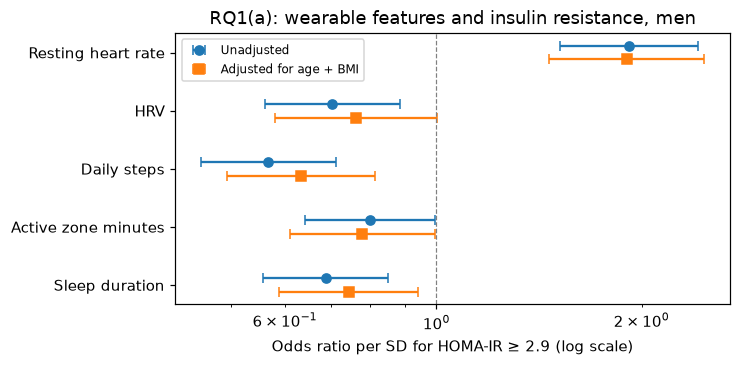

In [88]:
rq1a = pd.DataFrame({
    "Feature": A_adj["Feature"], "n": A_adj["n"],
    "OR per SD, unadjusted": fmt_or(A_unadj), "OR per SD, adjusted": fmt_or(A_adj),
    "p (adj.)": A_adj["p"].map("{:.2g}".format), "q BH (adj.)": A_adj["q (BH)"].map("{:.2g}".format),
    "% diff. HOMA-IR per SD, adjusted": fmt_or(A_lin, logit=False), "q BH (linear)": A_lin["q (BH)"].map("{:.2g}".format),
})
save_table(rq1a, "2.1_rq1_associations_men")
display(rq1a)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
yy = np.arange(len(A_adj))[::-1]
for off, t, lab, mk in [(0.12, A_unadj, "Unadjusted", "o"), (-0.12, A_adj, "Adjusted for age + BMI", "s")]:
    orr = np.exp(t["beta"]); lo = np.exp(t["beta"] - 1.96 * t["se"]); hi = np.exp(t["beta"] + 1.96 * t["se"])
    ax.errorbar(orr, yy + off, xerr=[orr - lo, hi - orr], fmt=mk, capsize=3, label=lab)
ax.axvline(1, color="grey", lw=0.8, ls="--")
ax.set_yticks(yy); ax.set_yticklabels(A_adj["Feature"]); ax.set_xscale("log")
ax.set_xlabel("Odds ratio per SD for HOMA-IR ≥ 2.9 (log scale)"); ax.legend(fontsize=8, loc="best")
ax.set_title("RQ1(a): wearable features and insulin resistance, men")
save_fig(fig, "2.1_rq1_forest_men"); plt.show()

## 2.2 Incremental cross-validated value

**What:** adds each feature (and each domain) alone to the age + BMI model (M0) and compares cross-validated AUROC on identical folds.  
**Inputs:** `men`, `FOLDS_M`, `BOOT_M`.  
**Outputs:** `2.2_rq1_incremental_men.csv`. Cached as `rq1b_incremental`.

**Run**

In [89]:
def _run_rq1b():
    out = {"M0": run_cv(men, "ir", TIERS["M0"], "LR", FOLDS_M)}
    for name, cols in [(LABEL[f], [f]) for f in WEAR] + list(DOMAINS.items()):
        out[name] = run_cv(men, "ir", BASE + cols, "LR", FOLDS_M)
    return out
RQ1B = cached("rq1b_incremental", _run_rq1b)
RES[("men", "LR", "M0")] = RQ1B["M0"]

Loaded from cache: rq1b_incremental


**Evaluate**

In [90]:
rows = []
for name, cols in [(LABEL[f], [f]) for f in WEAR] + list(DOMAINS.items()):
    res = RQ1B[name]
    c = contrast(res, RQ1B["M0"], BOOT_M)
    rows.append({"Added to M0": name,
                 "AUROC": stat_per_rep(res, auc).mean(), "ΔAUROC": c["Delta"], "lo": c["lo"], "hi": c["hi"],
                 "p (corrected t)": c["p (corrected t)"]})
rq1b = pd.DataFrame(rows)
rq1b["Level"] = ["feature"] * len(WEAR) + ["domain"] * len(DOMAINS)
rq1b["ΔAUROC (95% CI)"] = [fmt_ci(a, b, c) for a, b, c in zip(rq1b["ΔAUROC"], rq1b["lo"], rq1b["hi"])]
save_table(rq1b, "2.2_rq1_incremental_men")
rq1b[["Added to M0", "Level", "AUROC", "ΔAUROC (95% CI)", "p (corrected t)"]].round(3)

,Added to M0,Level,AUROC,ΔAUROC (95% CI),p (corrected t)
0,Resting heart rate,feature,0.782,0.032 (0.003 to 0.061),0.051
1,HRV,feature,0.753,0.002 (-0.011 to 0.017),0.709
2,Daily steps,feature,0.763,0.012 (-0.015 to 0.039),0.385
3,Active zone minutes,feature,0.751,0.000 (-0.014 to 0.015),0.922
4,Sleep duration,feature,0.754,0.004 (-0.013 to 0.019),0.610
5,Cardiac (RHR + HRV),domain,0.781,0.030 (0.001 to 0.060),0.061
6,Activity (steps + AZM),domain,0.760,0.009 (-0.018 to 0.038),0.522
7,Sleep,domain,0.754,0.004 (-0.013 to 0.019),0.610


## 2.3 Bootstrap rank stability

**What:** refits the adjusted associations on bootstrap samples and ranks features by absolute adjusted log-odds ratio per SD.  
**Inputs:** `men` (complete cases for the five features).  
**Outputs:** `2.3_rq1_rank_stability_men.csv` and bar chart. Cached as `rq1c_ranks`.

**Run**

In [91]:
def _run_rq1c():
    cc = men[["ir"] + BASE + WEAR].dropna().reset_index(drop=True)
    Z = (cc[WEAR] - cc[WEAR].mean()) / cc[WEAR].std()
    Xb, yv = cc[BASE].to_numpy(), cc["ir"].to_numpy()
    rng = np.random.default_rng(SEED)
    ranks = []
    for b in range(N_BOOT_RANK):
        ix = rng.integers(0, len(cc), len(cc))
        mags = []
        for f in WEAR:
            X = sm.add_constant(np.column_stack([Z[f].to_numpy()[ix], Xb[ix]]))
            try:
                mags.append(abs(sm.Logit(yv[ix], X).fit(disp=0).params[1]))
            except Exception:
                mags.append(np.nan)
        ranks.append(stats.rankdata(-np.array(mags)))
    return np.array(ranks)
ranks = cached("rq1c_ranks", _run_rq1c)

Loaded from cache: rq1c_ranks


**Evaluate**

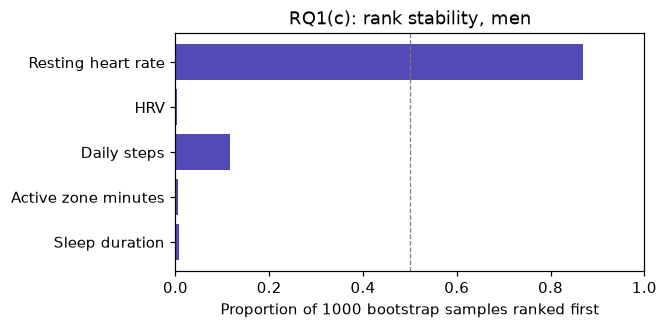

,Feature,P(ranked first),Mean rank
0,Resting heart rate,0.869,1.146
1,HRV,0.003,3.700
2,Daily steps,0.116,2.269
3,Active zone minutes,0.005,3.880
4,Sleep duration,0.007,4.005


In [92]:
rq1c = pd.DataFrame({"Feature": [LABEL[f] for f in WEAR],
                     "P(ranked first)": (ranks == 1).mean(axis=0), "Mean rank": ranks.mean(axis=0)})
save_table(rq1c, "2.3_rq1_rank_stability_men")

fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.barh(rq1c["Feature"][::-1], rq1c["P(ranked first)"][::-1], color="#534AB7")
ax.axvline(0.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel(f"Proportion of {N_BOOT_RANK} bootstrap samples ranked first"); ax.set_xlim(0, 1)
ax.set_title("RQ1(c): rank stability, men")
save_fig(fig, "2.3_rq1_rank_stability_men"); plt.show()
rq1c.round(3)

## 2.4 Interpret: decision rule for RQ1

**How to read this.** A feature is declared *strongest* only if it leads on all three lenses (largest adjusted association,
largest ΔAUROC over M0, ranked first in ≥ 50% of bootstraps). Otherwise the answer is given at domain level.

In [93]:
top_a = A_adj.loc[A_adj["beta"].abs().idxmax(), "Feature"]
feat_b = rq1b[rq1b["Level"] == "feature"]
top_b = feat_b.loc[feat_b["ΔAUROC"].idxmax(), "Added to M0"]
top_c = rq1c.loc[rq1c["P(ranked first)"].idxmax()]
strongest = top_a if (top_a == top_b == top_c["Feature"] and top_c["P(ranked first)"] >= 0.5) else None

dom = rq1b[rq1b["Level"] == "domain"].sort_values("ΔAUROC", ascending=False)
RQ1_DECISION = {
    "Lens (a) top feature (largest adjusted |log OR| per SD)": top_a,
    "Lens (b) top feature (largest ΔAUROC over M0)": top_b,
    "Lens (c) most often ranked first": f"{top_c['Feature']} ({top_c['P(ranked first)']:.0%} of bootstraps)",
    "Decision": (f"'{strongest}' is the strongest wearable feature (all three lenses agree, ≥50% of bootstraps)"
                 if strongest else "No single strongest feature: the lenses disagree or rank stability < 50%; report domains"),
    "Domain ranking by ΔAUROC over M0": " > ".join(f"{r['Added to M0']} ({r['ΔAUROC']:+.3f})" for _, r in dom.iterrows()),
}
pd.Series(RQ1_DECISION).to_frame("RQ1 result").to_csv(TAB_DIR / "2.4_rq1_decision.csv")
for k, v in RQ1_DECISION.items():
    print(f"{k}: {v}")

Lens (a) top feature (largest adjusted |log OR| per SD): Resting heart rate
Lens (b) top feature (largest ΔAUROC over M0): Resting heart rate
Lens (c) most often ranked first: Resting heart rate (87% of bootstraps)
Decision: 'Resting heart rate' is the strongest wearable feature (all three lenses agree, ≥50% of bootstraps)
Domain ranking by ΔAUROC over M0: Cardiac (RHR + HRV) (+0.030) > Activity (steps + AZM) (+0.009) > Sleep (+0.004)


# Part 3: RQ2, do wearables improve detection (men)

Six nested tiers, three models, identical folds. Primary contrasts: M1 vs M0, M3 vs M2, M5 vs M4
(penalised logistic regression; likelihood-ratio tests of the wearable block, Holm-corrected, in 3.6). XGBoost and EBM are secondary / exploratory.

## 3.1 Run: cross-validation, 6 tiers × 3 models

**What:** fits every tier with every model using the fixed folds (logistic regression: 100 outer folds; XGBoost and EBM: 50).  
**Inputs:** `men`, `TIERS`, `FOLDS_M`, `FOLDS_M_SEC`.  
**Outputs:** out-of-fold predictions in `RES`, used by 3.2 to 3.5. Cached as `rq2_cv_men` (the longest step of the notebook).

In [94]:
def _run_rq2():
    out = {}
    for model in ["LR", "XGB", "EBM"]:
        folds = FOLDS_M if model == "LR" else FOLDS_M_SEC
        for t, feats in TIERS.items():
            key = ("men", model, t)
            out[key] = RES[key] if key in RES else run_cv(men, "ir", feats, model, folds)
        timer(f"RQ2 {model}: all tiers done")
    return out
RES.update(cached("rq2_cv_men", _run_rq2))

Loaded from cache: rq2_cv_men


## 3.2 Evaluate: performance tables

**What:** summarises each model and tier: AUROC with bootstrap CI (headline estimate), AUPRC, Brier score, calibration, and a seven-metric table as mean ± SD across outer folds.  
**Inputs:** `RES`, `BOOT_M`.  
**Outputs:** `3.2_rq2_performance_men.csv`, `3.2_rq2_7metrics_men.csv`, `3.2_rq2_7metrics_men_numeric.csv`.

Threshold-dependent metrics use the threshold chosen inside each training fold (Youden index), not a fixed 0.5. EBM has no threshold, so its threshold-dependent metrics are blank. The ± SD values show spread across folds; report the bootstrap CIs as uncertainty.

In [95]:
perf = []
for model in ["LR", "XGB", "EBM"]:
    for t in TIERS:
        s = summarize(RES[("men", model, t)], BOOT_M)
        perf.append({"Model": MODEL_NAME[model], "Tier": t, "Features": TIER_DESC[t],
                     "AUROC (95% CI)": fmt_ci(s["AUROC"], s["AUROC lo"], s["AUROC hi"]), **s})
perf = pd.DataFrame(perf)
save_table(perf, "3.2_rq2_performance_men")
show_cols = ["Model", "Tier", "Features", "AUROC (95% CI)", "AUPRC", "Brier", "Cal. slope", "Cal. intercept",
             "Sensitivity", "Specificity", "Repeats"]
perf[show_cols].round(3)

,Model,Tier,Features,AUROC (95% CI),AUPRC,Brier,Cal. slope,Cal. intercept,Sensitivity,Specificity,Repeats
0,Penalised logistic regression,M0,Age + BMI,0.751 (0.700 to 0.801),0.468,0.155,1.008,-0.001,0.681,0.684,20
1,Penalised logistic regression,M1,M0 + wearables,0.791 (0.743 to 0.838),0.551,0.142,0.974,-0.004,0.708,0.724,20
2,Penalised logistic regression,M2,"M0 + TG, HDL, HbA1c",0.793 (0.744 to 0.839),0.555,0.141,1.044,-0.001,0.785,0.666,20
3,Penalised logistic regression,M3,M2 + wearables,0.816 (0.770 to 0.861),0.600,0.133,1.013,0.000,0.756,0.755,20
4,Penalised logistic regression,M4,M2 + fasting glucose,0.844 (0.805 to 0.880),0.631,0.129,1.026,-0.003,0.833,0.704,20
5,Penalised logistic regression,M5,M4 + wearables,0.857 (0.820 to 0.894),0.658,0.122,1.023,-0.001,0.779,0.785,20
6,XGBoost (shallow),M0,Age + BMI,0.735 (0.684 to 0.786),0.433,0.156,0.919,0.014,0.644,0.690,10
7,XGBoost (shallow),M1,M0 + wearables,0.776 (0.727 to 0.824),0.535,0.144,0.931,0.008,0.692,0.721,10
8,XGBoost (shallow),M2,"M0 + TG, HDL, HbA1c",0.789 (0.740 to 0.835),0.528,0.143,0.895,0.016,0.713,0.717,10
9,XGBoost (shallow),M3,M2 + wearables,0.808 (0.758 to 0.852),0.604,0.134,0.891,0.032,0.691,0.762,10


In [96]:
FOLD_METRICS = {}
for model in ["LR", "XGB", "EBM"]:
    folds = FOLDS_M if model == "LR" else FOLDS_M_SEC
    for t in TIERS:
        FOLD_METRICS[(model, t)] = fold_metrics(RES[("men", model, t)], folds)

rows, num_rows = [], []
for (model, t), fm in FOLD_METRICS.items():
    row = {"Model": MODEL_NAME[model], "Tier": t, "Features": TIER_DESC[t], "Folds": len(fm)}
    for k in METRIC_KEYS:
        row[k] = "-" if fm[k].isna().all() else f"{fm[k].mean():.3f} ± {fm[k].std():.3f}"
        num_rows.append({"Model": MODEL_NAME[model], "Tier": t, "Metric": k, "Mean": fm[k].mean(), "SD": fm[k].std()})
    rows.append(row)
metrics7 = pd.DataFrame(rows)
save_table(metrics7, "3.2_rq2_7metrics_men")
save_table(pd.DataFrame(num_rows).round(4), "3.2_rq2_7metrics_men_numeric")
metrics7

,Model,Tier,Features,Folds,AUROC,AUPRC,Accuracy,Precision,Sensitivity/Recall,Specificity,F1
0,Penalised logistic regression,M0,Age + BMI,100,0.754 ± 0.047,0.495 ± 0.072,0.683 ± 0.051,0.400 ± 0.055,0.680 ± 0.121,0.684 ± 0.081,0.499 ± 0.059
1,Penalised logistic regression,M1,M0 + wearables,100,0.796 ± 0.053,0.584 ± 0.089,0.720 ± 0.051,0.444 ± 0.066,0.708 ± 0.118,0.724 ± 0.073,0.541 ± 0.067
2,Penalised logistic regression,M2,"M0 + TG, HDL, HbA1c",100,0.795 ± 0.044,0.577 ± 0.077,0.694 ± 0.042,0.418 ± 0.044,0.785 ± 0.098,0.666 ± 0.057,0.544 ± 0.053
3,Penalised logistic regression,M3,M2 + wearables,100,0.820 ± 0.049,0.627 ± 0.084,0.755 ± 0.042,0.487 ± 0.057,0.756 ± 0.110,0.755 ± 0.055,0.589 ± 0.065
4,Penalised logistic regression,M4,M2 + fasting glucose,100,0.846 ± 0.040,0.650 ± 0.072,0.734 ± 0.044,0.465 ± 0.051,0.833 ± 0.091,0.703 ± 0.065,0.594 ± 0.048
5,Penalised logistic regression,M5,M4 + wearables,100,0.859 ± 0.042,0.678 ± 0.076,0.784 ± 0.040,0.529 ± 0.063,0.779 ± 0.089,0.785 ± 0.052,0.627 ± 0.057
6,XGBoost (shallow),M0,Age + BMI,50,0.741 ± 0.048,0.474 ± 0.077,0.679 ± 0.068,0.397 ± 0.062,0.642 ± 0.127,0.690 ± 0.107,0.482 ± 0.059
7,XGBoost (shallow),M1,M0 + wearables,50,0.782 ± 0.053,0.577 ± 0.100,0.714 ± 0.045,0.434 ± 0.058,0.692 ± 0.104,0.721 ± 0.065,0.529 ± 0.057
8,XGBoost (shallow),M2,"M0 + TG, HDL, HbA1c",50,0.795 ± 0.043,0.570 ± 0.088,0.716 ± 0.058,0.441 ± 0.062,0.712 ± 0.124,0.717 ± 0.090,0.538 ± 0.064
9,XGBoost (shallow),M3,M2 + wearables,50,0.813 ± 0.045,0.626 ± 0.090,0.745 ± 0.045,0.477 ± 0.070,0.690 ± 0.139,0.762 ± 0.078,0.555 ± 0.067


## 3.3 Evaluate: ROC curves and metrics by model

**What:** plots ROC curves by tier for each model, the seven metrics by model, and AUROC by tier.  
**Inputs:** `RES`, `FOLD_METRICS`, `perf`.  
**Outputs:** `3.3_rq2_roc_curves_men.png`, `3.3_rq2_metrics_by_model_men.png`, `3.3_rq2_auroc_by_tier_men.png`.

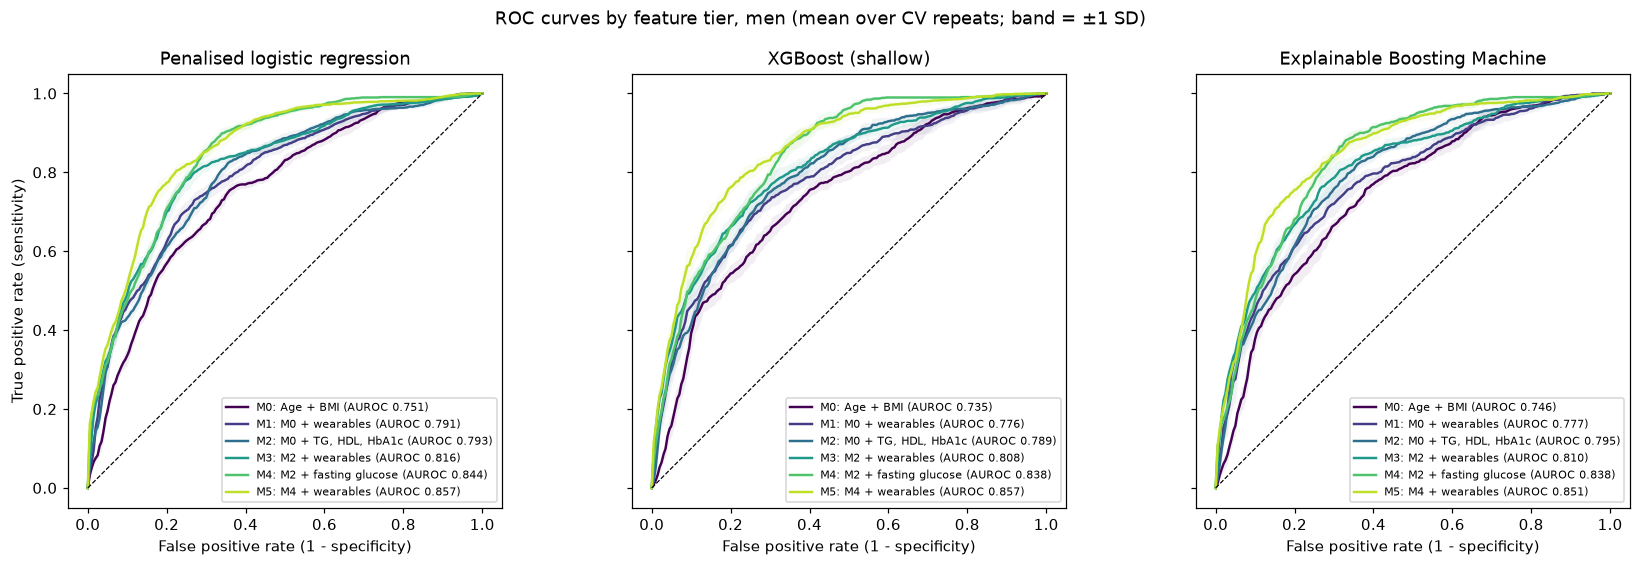

In [97]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(TIERS)))
for ax, model in zip(axes, ["LR", "XGB", "EBM"]):
    for col, t in zip(colors, TIERS):
        res = RES[("men", model, t)]
        m, s = mean_roc(res)
        a = stat_per_rep(res, auc).mean()
        ax.plot(FPR_GRID, m, color=col, lw=1.6, label=f"{t}: {TIER_DESC[t]} (AUROC {a:.3f})")
        ax.fill_between(FPR_GRID, np.clip(m - s, 0, 1), np.clip(m + s, 0, 1), color=col, alpha=0.07, lw=0)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(MODEL_NAME[model]); ax.set_xlabel("False positive rate (1 - specificity)")
    ax.legend(fontsize=7, loc="lower right"); ax.set_aspect("equal")
axes[0].set_ylabel("True positive rate (sensitivity)")
fig.suptitle("ROC curves by feature tier, men (mean over CV repeats; band = ±1 SD)", y=1.0)
fig.tight_layout(); save_fig(fig, "3.3_rq2_roc_curves_men"); plt.show()

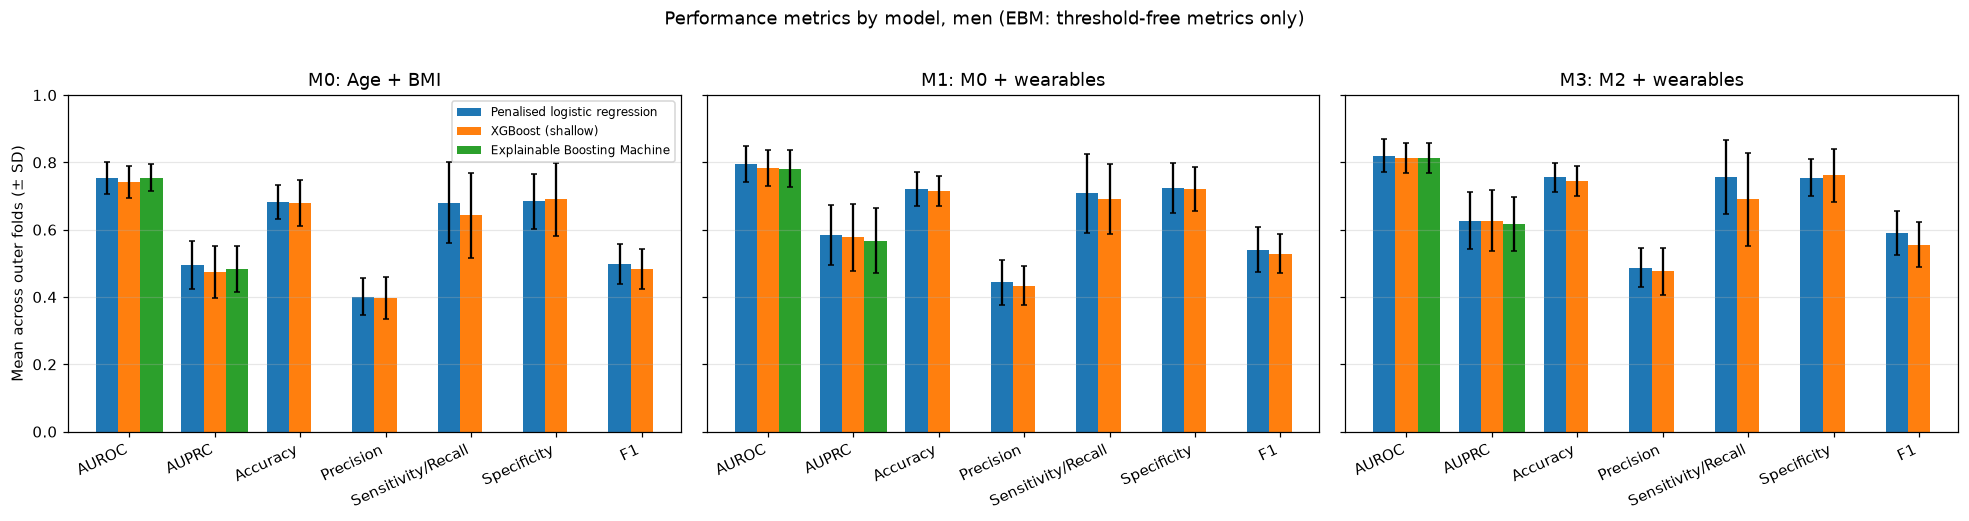

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
w, xs = 0.26, np.arange(len(METRIC_KEYS))
for ax, t in zip(axes, ["M0", "M1", "M3"]):
    for k, model in enumerate(["LR", "XGB", "EBM"]):
        fm = FOLD_METRICS[(model, t)]
        means, sds = fm[METRIC_KEYS].mean().to_numpy(), fm[METRIC_KEYS].std().to_numpy()
        ok = np.isfinite(means)
        ax.bar(xs[ok] + (k - 1) * w, means[ok], w, yerr=sds[ok], capsize=2, label=MODEL_NAME[model])
    ax.set_xticks(xs); ax.set_xticklabels(METRIC_KEYS, rotation=25, ha="right")
    ax.set_title(f"{t}: {TIER_DESC[t]}"); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Mean across outer folds (± SD)"); axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Performance metrics by model, men (EBM: threshold-free metrics only)", y=1.02)
fig.tight_layout(); save_fig(fig, "3.3_rq2_metrics_by_model_men"); plt.show()

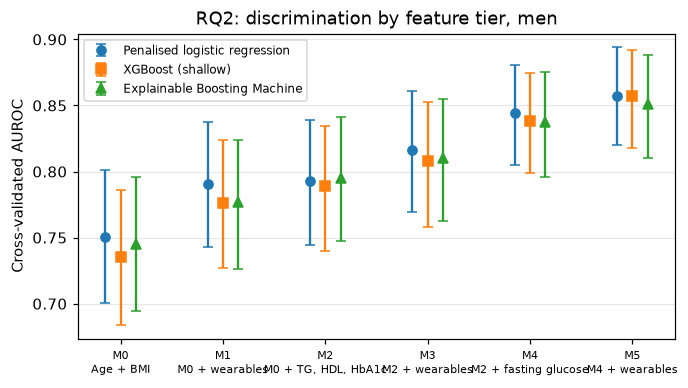

In [99]:
fig, ax = plt.subplots(figsize=(7, 3.6))
xs = np.arange(len(TIERS))
for k, (model, mk) in enumerate([("LR", "o"), ("XGB", "s"), ("EBM", "^")]):
    p = perf[perf["Model"] == MODEL_NAME[model]]
    ax.errorbar(xs + (k - 1) * 0.15, p["AUROC"], yerr=[p["AUROC"] - p["AUROC lo"], p["AUROC hi"] - p["AUROC"]],
                fmt=mk, capsize=3, label=MODEL_NAME[model])
ax.set_xticks(xs); ax.set_xticklabels([f"{t}\n{TIER_DESC[t]}" for t in TIERS], fontsize=7.5)
ax.set_ylabel("Cross-validated AUROC"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
ax.set_title("RQ2: discrimination by feature tier, men")
save_fig(fig, "3.3_rq2_auroc_by_tier_men"); plt.show()

## 3.4 Evaluate: paired contrasts

**What:** estimates how much adding wearables improves AUROC at each level of baseline information (paired bootstrap 95% CI). The change in AUROC is an effect size and is not tested here; the significance test for RQ2 is the likelihood-ratio test in 3.6.  
**Inputs:** `RES`, `BOOT_M`.  
**Outputs:** `3.4_rq2_contrasts_men.csv`.

In [100]:
con = []
for model in ["LR", "XGB", "EBM"]:
    for big, small in CONTRASTS:
        c = contrast(RES[("men", model, big)], RES[("men", model, small)], BOOT_M)
        con.append({"Model": MODEL_NAME[model], "Contrast": f"{big} vs {small}",
                    "Question": {"M1": "Beyond age + BMI", "M3": "Beyond routine blood panel",
                                 "M5": "Beyond panel + glucose"}[big], **c})
con = pd.DataFrame(con).drop(columns=["p (corrected t)"])   # ΔAUROC is an effect size; RQ2 is tested in 3.6
con["ΔAUROC (95% CI)"] = [fmt_ci(a, b, c) for a, b, c in zip(con["Delta"], con["lo"], con["hi"])]
def conclusion(r):
    if r["Δ ≥ 0.02"] and r["CI excludes 0"]:
        return "Meaningful improvement (≥ 0.02, CI excludes 0)"
    if r["CI excludes 0"] and r["Delta"] > 0:
        return "Detectable improvement, below 0.02"
    if r["CI excludes 0"] and r["Delta"] < 0:
        return "Worse than baseline"
    return "No clear improvement"
con["Conclusion"] = con.apply(conclusion, axis=1)
save_table(con, "3.4_rq2_contrasts_men")
con[["Model", "Contrast", "Question", "ΔAUROC (95% CI)", "Conclusion"]]

,Model,Contrast,Question,ΔAUROC (95% CI),Conclusion
0,Penalised logistic regression,M1 vs M0,Beyond age + BMI,0.040 (0.005 to 0.074),"Meaningful improvement (≥ 0.02, CI excludes 0)"
1,Penalised logistic regression,M3 vs M2,Beyond routine blood panel,0.023 (-0.001 to 0.047),No clear improvement
2,Penalised logistic regression,M5 vs M4,Beyond panel + glucose,0.013 (-0.006 to 0.031),No clear improvement
3,XGBoost (shallow),M1 vs M0,Beyond age + BMI,0.041 (0.005 to 0.077),"Meaningful improvement (≥ 0.02, CI excludes 0)"
4,XGBoost (shallow),M3 vs M2,Beyond routine blood panel,0.019 (-0.011 to 0.048),No clear improvement
5,XGBoost (shallow),M5 vs M4,Beyond panel + glucose,0.019 (-0.004 to 0.042),No clear improvement
6,Explainable Boosting Machine,M1 vs M0,Beyond age + BMI,0.031 (-0.006 to 0.068),No clear improvement
7,Explainable Boosting Machine,M3 vs M2,Beyond routine blood panel,0.015 (-0.012 to 0.043),No clear improvement
8,Explainable Boosting Machine,M5 vs M4,Beyond panel + glucose,0.013 (-0.010 to 0.036),No clear improvement


## 3.5 Evaluate: calibration and decision curves

**What:** checks calibration (decile plot) and clinical usefulness (net benefit across risk thresholds; pre-specified 10-40%).  
**Inputs:** `RES` (penalised logistic regression).  
**Outputs:** `3.5_rq2_calibration_dca_men.png`, `3.5_rq2_decision_curve_men.csv`.

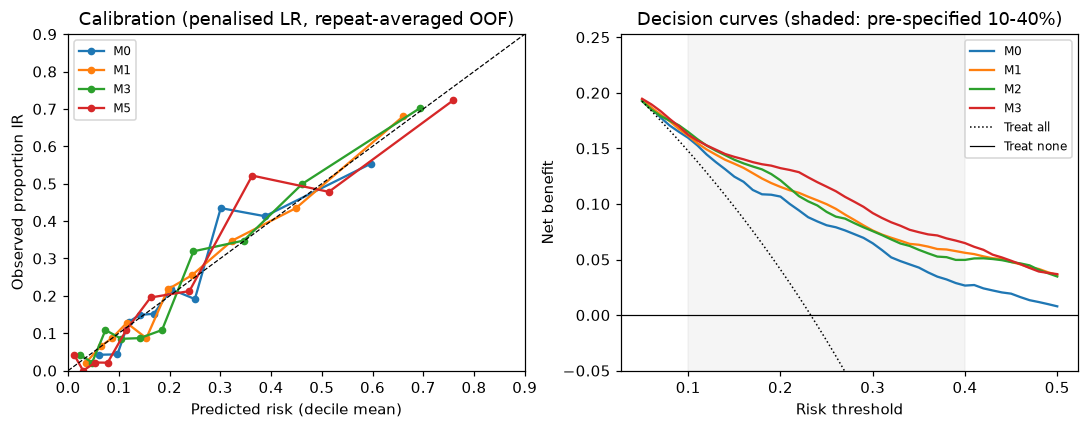

,threshold,M0,M1,M2,M3,treat_all
0,0.05,0.1934,0.1942,0.1924,0.1946,0.1924
1,0.06,0.1862,0.1867,0.1849,0.1896,0.1838
2,0.07,0.1778,0.1806,0.1791,0.1835,0.1750
3,0.08,0.1705,0.1744,0.1749,0.1764,0.1660
4,0.09,0.1648,0.1674,0.1707,0.1698,0.1569
5,0.10,0.1595,0.1614,0.1647,0.1622,0.1475
6,0.11,0.1526,0.1546,0.1583,0.1570,0.1379
7,0.12,0.1445,0.1490,0.1525,0.1527,0.1281
8,0.13,0.1376,0.1443,0.1479,0.1488,0.1181
9,0.14,0.1313,0.1397,0.1439,0.1450,0.1079


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
for t in ["M0", "M1", "M3", "M5"]:
    res = RES[("men", "LR", t)]; pbar = np.nanmean(res["P"], axis=0)
    bins = pd.qcut(pbar, 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": pbar, "y": res["y"], "b": bins}).groupby("b").mean()
    ax.plot(g["p"], g["y"], "o-", ms=4, label=t)
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlim(0, 0.9); ax.set_ylim(0, 0.9)
ax.set_xlabel("Predicted risk (decile mean)"); ax.set_ylabel("Observed proportion IR")
ax.set_title("Calibration (penalised LR, repeat-averaged OOF)"); ax.legend(fontsize=8)

ax = axes[1]; th = np.linspace(0.05, 0.5, 46); y = RES[("men", "LR", "M0")]["y"]
dca = pd.DataFrame({"threshold": th})
for t in ["M0", "M1", "M2", "M3"]:
    res = RES[("men", "LR", t)]
    dca[t] = np.mean([net_benefit(y, res["P"][r], th) for r in range(res["P"].shape[0])], axis=0)
    ax.plot(th, dca[t], label=t)
prev = y.mean()
dca["treat_all"] = prev - (1 - prev) * th / (1 - th)
ax.plot(th, dca["treat_all"], "k:", lw=1, label="Treat all")
ax.axhline(0, color="k", lw=0.8, label="Treat none"); ax.axvspan(0.10, 0.40, color="grey", alpha=0.08)
ax.set_ylim(-0.05, prev + 0.02); ax.set_xlabel("Risk threshold"); ax.set_ylabel("Net benefit")
ax.set_title("Decision curves (shaded: pre-specified 10-40%)"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "3.5_rq2_calibration_dca_men"); plt.show()
save_table(dca.round(4), "3.5_rq2_decision_curve_men")

## 3.6 Additional evidence for RQ2: effect sizes beyond the p-value

This section gives the significance test for RQ2 and the measures recommended for judging whether new predictors improve a model:

| Measure | Question it answers | Reference |
|---|---|---|
| Likelihood-ratio test of the wearable block (nested logistic, 5 df), ΔAIC, ΔBIC, Nagelkerke R² | Do the wearables carry information beyond the smaller model? The recommended *test* for nested models | Vickers et al. 2011; Pepe et al. 2013; Demler et al. 2012 |
| ΔAUROC, ΔAUPRC | How much better is ranking of IR vs non-IR? (effect size, 95% CI) | Steyerberg et al. 2010 |
| ΔBrier, ΔIPA (scaled Brier) | How much more accurate are the predicted probabilities overall? | Kattan & Gerds 2018 |
| IDI (Δ discrimination slope) | How much further apart are mean predicted risks of IR and non-IR men? | Pencina et al. 2008 |
| Δ net benefit | Is the model more useful for decisions at clinically plausible thresholds? | Vickers & Elkin 2006 |
| Bayesian correlated t-test | What is the probability that the gain is > 0 or ≥ 0.02? | Benavoli et al. 2017 |

**What:** computes the measures above for each primary contrast (penalised LR).
**Inputs:** `RES` (3.1), `BOOT_M`, `men`.
**Outputs:** `3.6_rq2_effect_sizes_men.csv`, `3.6_rq2_lrt_men.csv`, `3.6_rq2_bayes_men.csv`. Cached as `rq2_extra`.

**Run**

In [102]:
def _brier(y, p): return np.mean((p - y) ** 2)
def _ipa(y, p):   return 1 - _brier(y, p) / _brier(y, np.full_like(p, y.mean()))
def _dslope(y, p): return p[y == 1].mean() - p[y == 0].mean()
def _ll(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
def _nb(y, p, t): return ((p >= t) & (y == 1)).mean() - ((p >= t) & (y == 0)).mean() * t / (1 - t)
def _nri(y, pn, po):
    up, dn = pn > po, pn < po
    return np.array([up[y == 1].mean() - dn[y == 1].mean(), dn[y == 0].mean() - up[y == 0].mean()])

NB_THRESH = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
PAIR_FNS = {"ΔAUROC": lambda y, a, b: auc(y, a) - auc(y, b),
            "ΔAUPRC": lambda y, a, b: average_precision_score(y, a) - average_precision_score(y, b),
            "ΔBrier (negative = better)": lambda y, a, b: _brier(y, a) - _brier(y, b),
            "ΔIPA (scaled Brier)": lambda y, a, b: _ipa(y, a) - _ipa(y, b),
            "IDI (Δ discrimination slope)": lambda y, a, b: _dslope(y, a) - _dslope(y, b),
            "Δlog-loss (negative = better)": lambda y, a, b: _ll(y, a) - _ll(y, b),
            "NRI events (continuous)": lambda y, a, b: _nri(y, a, b)[0],
            "NRI non-events (continuous)": lambda y, a, b: _nri(y, a, b)[1]}
for t in NB_THRESH:
    PAIR_FNS[f"Δnet benefit per 100 @ {t:.0%}"] = (lambda y, a, b, t=t: 100 * (_nb(y, a, t) - _nb(y, b, t)))

def _pair_all(big, small, ix=None):
    y = big["y"] if ix is None else big["y"][ix]; R = min(big["P"].shape[0], small["P"].shape[0])
    vals = []
    for r in range(R):
        a, b = big["P"][r], small["P"][r]
        if ix is not None: a, b = a[ix], b[ix]
        vals.append([fn(y, a, b) for fn in PAIR_FNS.values()])
    return np.mean(vals, axis=0)

def _run_rq2_extra():
    out = {}
    for big, small in CONTRASTS:
        B, S = RES[("men", "LR", big)], RES[("men", "LR", small)]
        out[(big, small)] = {"point": _pair_all(B, S), "boot": np.array([_pair_all(B, S, ix) for ix in BOOT_M])}
    return out
RQ2X = cached("rq2_extra", _run_rq2_extra)

Loaded from cache: rq2_extra


**Evaluate**

In [103]:
# (a) Effect sizes with bootstrap 95% CI
rows = []
for (big, small), r in RQ2X.items():
    lo, hi = np.percentile(r["boot"], [2.5, 97.5], axis=0)
    for k, name in enumerate(PAIR_FNS):
        dec = 1 if name.startswith("Δnet") else 3
        rows.append({"Contrast": f"{big} vs {small}", "Measure": name, "Estimate": r["point"][k], "lo": lo[k], "hi": hi[k],
                     "Estimate (95% CI)": fmt_ci(r["point"][k], lo[k], hi[k], dec)})
eff = pd.DataFrame(rows)
save_table(eff, "3.6_rq2_effect_sizes_men")
display(eff.pivot(index="Measure", columns="Contrast", values="Estimate (95% CI)").loc[list(PAIR_FNS)])

# (b) Likelihood-ratio test of the wearable block (unpenalised nested logistic, same complete-case sample)
lrt = []
for big, small in CONTRASTS:
    cc = men[["ir"] + TIERS[big]].dropna(); n = len(cc)
    mb = sm.Logit(cc["ir"], sm.add_constant(cc[TIERS[big]])).fit(disp=0)
    ms = sm.Logit(cc["ir"], sm.add_constant(cc[TIERS[small]])).fit(disp=0)
    nag = lambda m: (1 - np.exp(2 * (m.llnull - m.llf) / n)) / (1 - np.exp(2 * m.llnull / n))
    chi2 = 2 * (mb.llf - ms.llf); dfree = len(TIERS[big]) - len(TIERS[small])
    lrt.append({"Contrast": f"{big} vs {small}", "n": n, "LR χ²": chi2, "df": dfree, "p": stats.chi2.sf(chi2, dfree),
                "ΔAIC (negative = better)": mb.aic - ms.aic, "ΔBIC (negative = better)": mb.bic - ms.bic,
                "Nagelkerke R², smaller model": nag(ms), "Nagelkerke R², larger model": nag(mb)})
lrt = pd.DataFrame(lrt); lrt["p (Holm)"] = multipletests(lrt["p"], method="holm")[1]
save_table(lrt, "3.6_rq2_lrt_men")
display(lrt.round(3).assign(**{"p": lrt["p"].map("{:.2g}".format), "p (Holm)": lrt["p (Holm)"].map("{:.2g}".format)}))

# (c) Bayesian correlated t-test on the same 100 fold-level ΔAUROCs used in 3.4 (rho = test fraction = 1/5)
bay = []
for big, small in CONTRASTS:
    d = RES[("men", "LR", big)]["fold_auc"] - RES[("men", "LR", small)]["fold_auc"]
    J, rho = len(d), 1 / N_SPLITS
    post = stats.t(df=J - 1, loc=d.mean(), scale=np.sqrt((1 / J + rho / (1 - rho)) * d.var(ddof=1)))
    bay.append({"Contrast": f"{big} vs {small}", "Mean fold ΔAUROC": d.mean(),
                "95% credible interval": f"{post.ppf(.025):.3f} to {post.ppf(.975):.3f}",
                "P(Δ > 0)": 1 - post.cdf(0), "P(Δ ≥ 0.02)": 1 - post.cdf(MIN_DAUROC),
                "P(|Δ| < 0.01), practically equivalent": post.cdf(0.01) - post.cdf(-0.01),
                "Folds where larger model won": f"{int((d > 0).sum())}/{J}"})
bay = pd.DataFrame(bay)
save_table(bay, "3.6_rq2_bayes_men")
display(bay.round(3))

Contrast,M1 vs M0,M3 vs M2,M5 vs M4
Measure,,,
ΔAUROC,0.040 (0.005 to 0.074),0.023 (-0.001 to 0.047),0.013 (-0.006 to 0.031)
ΔAUPRC,0.083 (0.024 to 0.141),0.045 (-0.005 to 0.093),0.027 (-0.012 to 0.065)
ΔBrier (negative = better),-0.012 (-0.021 to -0.004),-0.008 (-0.015 to -0.001),-0.007 (-0.014 to 0.000)
ΔIPA (scaled Brier),0.070 (0.019 to 0.117),0.045 (0.003 to 0.085),0.040 (-0.000 to 0.079)
IDI (Δ discrimination slope),0.069 (0.040 to 0.100),0.044 (0.020 to 0.067),0.034 (0.011 to 0.058)
Δlog-loss (negative = better),-0.030 (-0.054 to -0.005),-0.018 (-0.038 to 0.003),-0.016 (-0.035 to 0.004)
NRI events (continuous),0.211 (0.044 to 0.388),0.160 (-0.020 to 0.338),0.144 (-0.033 to 0.314)
NRI non-events (continuous),0.263 (0.167 to 0.355),0.251 (0.158 to 0.337),0.243 (0.154 to 0.329)
Δnet benefit per 100 @ 10%,0.2 (-1.1 to 1.5),-0.3 (-1.2 to 0.6),0.1 (-0.5 to 0.8)


,Contrast,n,LR χ²,df,p,ΔAIC (negative = better),ΔBIC (negative = better),"Nagelkerke R², smaller model","Nagelkerke R², larger model",p (Holm)
0,M1 vs M0,458,38.876,5,2.5e-07,-28.876,-8.242,0.201,0.308,7.5e-07
1,M3 vs M2,456,28.650,5,2.7e-05,-18.650,1.962,0.304,0.377,5.4e-05
2,M5 vs M4,456,25.598,5,0.00011,-15.598,5.014,0.415,0.475,0.00011


,Contrast,Mean fold ΔAUROC,95% credible interval,P(Δ > 0),P(Δ ≥ 0.02),"P(|Δ| < 0.01), practically equivalent",Folds where larger model won
0,M1 vs M0,0.042,0.005 to 0.079,0.987,0.881,0.041,85/100
1,M3 vs M2,0.025,-0.000 to 0.050,0.975,0.649,0.117,82/100
2,M5 vs M4,0.013,-0.009 to 0.035,0.876,0.256,0.380,70/100


**How to read this.** The likelihood-ratio test answers *whether* the wearables add information
(the correct significance test for nested models); ΔAUROC and the other measures describe *how much* they add, and are
reported as estimates with 95% CIs rather than tested again. NRI is shown as its two components only, because the
summed continuous NRI is known to overstate improvement (Pepe et al. 2015); treat it as supplementary.
The Bayesian probabilities use the fold-level ΔAUROCs from 3.4, with a correction for the overlap between training
folds, and give the probability of an improvement instead of a yes/no decision.

## 3.7 Evaluate: screening scenario

**What:** translates the gain over age and BMI into a referral decision. The scenario is a man with no recent blood test, and the model decides whether he is referred for a fasting blood test (HOMA-IR). Age and BMI alone (M0) are compared with age, BMI and the five smartwatch features (M1), penalised logistic regression, out-of-fold predictions from the same 20 repeats.

Three views:
1. **Risk threshold.** Refer a man if his predicted risk is at or above 10%, 20% or 30% (inside the pre-specified 10-40% decision-curve range).
2. **Net blood tests avoided.** The decision-curve net benefit converted to tests avoided per 100 men, against M0 and against testing everyone.
3. **Fixed capacity.** Only the top 20%, 30% or 40% of men by predicted risk can be referred.

Every value is the mean over the 20 repeats; 95% CIs come from the same 2,000 participant bootstrap samples used elsewhere (`BOOT_M`).
**Inputs:** `RES` (3.1), `BOOT_M`.
**Outputs:** `3.7_rq2_screening_threshold_men.csv`, `3.7_rq2_screening_tests_avoided_men.csv`, `3.7_rq2_screening_capacity_men.csv`, `3.7_rq2_referral_curve_men.png`. Cached as `rq2_screening`.

**Run**

In [104]:
SCREEN_T = [0.10, 0.20, 0.30]   # referral thresholds on predicted risk (inside the pre-specified 10-40% range)
SCREEN_K = [0.20, 0.30, 0.40]   # fixed referral capacity: share of men who can be referred
GAIN_GRID = np.round(np.arange(0, 1.0001, 0.01), 2)
SCREEN_COLS = ["Referred per 100", "IR found per 100", "IR missed per 100", "Unnecessary tests per 100",
               "Sensitivity", "Specificity", "PPV", "NPV", "Tests per IR case found"]

def _refer_stats(y, refer):
    n = len(y); tp = (refer & (y == 1)).sum(); fp = (refer & (y == 0)).sum()
    fn = (~refer & (y == 1)).sum(); tn = (~refer & (y == 0)).sum()
    return np.array([100 * refer.mean(), 100 * tp / n, 100 * fn / n, 100 * fp / n,
                     tp / (tp + fn), tn / (tn + fp),
                     tp / (tp + fp) if tp + fp else np.nan, tn / (tn + fn) if tn + fn else np.nan,
                     refer.sum() / tp if tp else np.nan])

def _top_k(p, k):
    refer = np.zeros(len(p), bool); refer[np.argsort(-p, kind="stable")[:int(round(k * len(p)))]] = True
    return refer

def _gain_curve(y, p):
    # share of insulin-resistant men found when the top x% by predicted risk are referred
    found = np.concatenate([[0], np.cumsum(y[np.argsort(-p, kind="stable")])]) / y.sum()
    return np.interp(GAIN_GRID * len(y), np.arange(len(y) + 1), found)

def _screen_one(y, p):
    out = {("thr", t): _refer_stats(y, p >= t) for t in SCREEN_T}
    out.update({("cap", k): _refer_stats(y, _top_k(p, k)) for k in SCREEN_K})
    out.update({("nb", t): np.array([_nb(y, p, t)]) for t in SCREEN_T})
    out["gain"] = _gain_curve(y, p)
    return out

def _screen_avg(res, ix=None):
    y = res["y"] if ix is None else res["y"][ix]
    reps = [_screen_one(y, res["P"][r] if ix is None else res["P"][r][ix]) for r in range(res["P"].shape[0])]
    return {k: np.nanmean([d[k] for d in reps], axis=0) for k in reps[0]}

def _run_screening():
    out = {}
    for t in ["M0", "M1"]:
        res = RES[("men", "LR", t)]
        out[t] = {"point": _screen_avg(res), "boot": [_screen_avg(res, ix) for ix in BOOT_M]}
    return out
SCREEN = cached("rq2_screening", _run_screening)

Loaded from cache: rq2_screening


**Evaluate**

,Refer if risk ≥,Measure,Age + BMI (M0),M0 + smartwatch (M1),"Difference, M1 - M0"
0,10%,Referred per 100,83.8 (80.5 to 86.9),69.7 (65.6 to 73.7),-14.1 (-17.7 to -10.9)
1,10%,IR found per 100,22.7 (18.9 to 26.8),21.5 (17.9 to 25.3),-1.2 (-2.5 to 0.0)
2,10%,IR missed per 100,0.5 (0.1 to 1.2),1.8 (0.8 to 3.0),1.2 (-0.0 to 2.5)
3,10%,Unnecessary tests per 100,61.1 (56.9 to 65.3),48.2 (43.9 to 52.5),-12.9 (-16.0 to -9.8)
4,10%,Sensitivity,0.977 (0.946 to 0.998),0.924 (0.876 to 0.966),-0.053 (-0.107 to 0.001)
5,10%,Specificity,0.204 (0.166 to 0.243),0.372 (0.324 to 0.420),0.168 (0.128 to 0.207)
6,10%,PPV,0.271 (0.228 to 0.317),0.309 (0.259 to 0.359),0.037 (0.020 to 0.056)
7,10%,NPV,0.967 (0.923 to 0.997),0.941 (0.903 to 0.974),-0.025 (-0.074 to 0.028)
8,10%,Tests per IR case found,3.7 (3.2 to 4.4),3.2 (2.8 to 3.9),-0.4 (-0.7 to -0.2)
9,20%,Referred per 100,45.4 (40.8 to 49.8),44.3 (40.0 to 48.4),-1.2 (-4.8 to 2.1)


,Refer if risk ≥,"Extra IR men found per 100, M1 vs M0 (net)","Net tests avoided per 100, M1 vs M0","Net tests avoided per 100, M0 vs testing everyone","Net tests avoided per 100, M1 vs testing everyone"
0,10%,0.2 (-1.1 to 1.5),1.8 (-10.1 to 13.7),10.8 (3.6 to 16.4),12.5 (0.7 to 22.6)
1,20%,0.9 (-0.6 to 2.4),3.5 (-2.6 to 9.8),26.3 (15.8 to 36.6),29.8 (19.8 to 39.2)
2,30%,1.2 (-1.1 to 3.5),2.7 (-2.6 to 8.1),37.5 (28.1 to 47.0),40.2 (31.2 to 48.8)


,Share referred,Measure,Age + BMI (M0),M0 + smartwatch (M1),"Difference, M1 - M0"
1,20%,IR found per 100,9.9 (7.8 to 11.9),11.2 (9.0 to 13.3),1.4 (-0.2 to 2.9)
2,20%,IR missed per 100,13.4 (10.2 to 16.6),12.0 (9.1 to 15.1),-1.4 (-2.9 to 0.2)
3,20%,Unnecessary tests per 100,10.2 (8.2 to 12.2),8.8 (6.7 to 11.0),-1.4 (-2.9 to 0.2)
4,20%,Sensitivity,0.425 (0.355 to 0.504),0.483 (0.415 to 0.559),0.058 (-0.010 to 0.125)
5,20%,Specificity,0.868 (0.845 to 0.890),0.885 (0.860 to 0.910),0.018 (-0.003 to 0.039)
6,20%,PPV,0.494 (0.389 to 0.592),0.561 (0.451 to 0.665),0.068 (-0.011 to 0.144)
7,20%,NPV,0.833 (0.792 to 0.873),0.850 (0.811 to 0.886),0.017 (-0.003 to 0.036)
10,30%,IR found per 100,13.7 (11.0 to 16.2),14.5 (12.1 to 17.0),0.9 (-0.7 to 2.5)
11,30%,IR missed per 100,9.6 (7.1 to 12.3),8.7 (6.2 to 11.5),-0.9 (-2.5 to 0.7)
12,30%,Unnecessary tests per 100,16.3 (13.7 to 18.9),15.4 (13.0 to 17.9),-0.9 (-2.5 to 0.7)


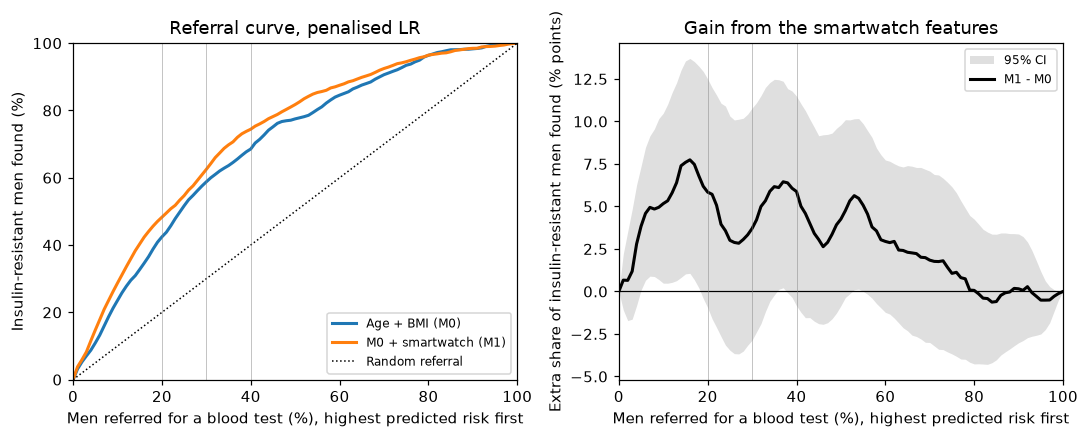

In [105]:
def _ci(vals, d):
    lo, hi = np.nanpercentile(vals, [2.5, 97.5]); return lo, hi

def _fmt(est, boots, d=1):
    lo, hi = _ci(boots, d); return f"{est:.{d}f} ({lo:.{d}f} to {hi:.{d}f})"

def _screen_table(kind, levels, label):
    rows = []
    for lv in levels:
        for j, col in enumerate(SCREEN_COLS):
            d = 3 if col in ("Sensitivity", "Specificity", "PPV", "NPV") else 1
            v0 = SCREEN["M0"]["point"][(kind, lv)][j]; v1 = SCREEN["M1"]["point"][(kind, lv)][j]
            b0 = np.array([b[(kind, lv)][j] for b in SCREEN["M0"]["boot"]])
            b1 = np.array([b[(kind, lv)][j] for b in SCREEN["M1"]["boot"]])
            rows.append({label: f"{lv:.0%}", "Measure": col, "Age + BMI (M0)": _fmt(v0, b0, d),
                         "M0 + smartwatch (M1)": _fmt(v1, b1, d), "Difference, M1 - M0": _fmt(v1 - v0, b1 - b0, d)})
    return pd.DataFrame(rows)

# (a) Referral by risk threshold
scr_thr = _screen_table("thr", SCREEN_T, "Refer if risk ≥")
save_table(scr_thr, "3.7_rq2_screening_threshold_men")
display(scr_thr)

# (b) Net blood tests avoided per 100 men (decision-curve net benefit / threshold odds)
prev = RES[("men", "LR", "M0")]["y"].mean()
rows = []
for t in SCREEN_T:
    w = t / (1 - t); nb_all = prev - (1 - prev) * w
    nb0 = SCREEN["M0"]["point"][("nb", t)][0]; nb1 = SCREEN["M1"]["point"][("nb", t)][0]
    b0 = np.array([b[("nb", t)][0] for b in SCREEN["M0"]["boot"]]); b1 = np.array([b[("nb", t)][0] for b in SCREEN["M1"]["boot"]])
    yb = [RES[("men", "LR", "M0")]["y"][ix].mean() for ix in BOOT_M]
    ball = np.array([pv - (1 - pv) * w for pv in yb])
    rows.append({"Refer if risk ≥": f"{t:.0%}",
                 "Extra IR men found per 100, M1 vs M0 (net)": _fmt(100 * (nb1 - nb0), 100 * (b1 - b0)),
                 "Net tests avoided per 100, M1 vs M0": _fmt(100 * (nb1 - nb0) / w, 100 * (b1 - b0) / w),
                 "Net tests avoided per 100, M0 vs testing everyone": _fmt(100 * (nb0 - nb_all) / w, 100 * (b0 - ball) / w),
                 "Net tests avoided per 100, M1 vs testing everyone": _fmt(100 * (nb1 - nb_all) / w, 100 * (b1 - ball) / w)})
scr_nb = pd.DataFrame(rows)
save_table(scr_nb, "3.7_rq2_screening_tests_avoided_men")
display(scr_nb)

# (c) Fixed referral capacity
scr_cap = _screen_table("cap", SCREEN_K, "Share referred")
scr_cap = scr_cap[~scr_cap["Measure"].isin(["Referred per 100", "Tests per IR case found"])]
save_table(scr_cap, "3.7_rq2_screening_capacity_men")
display(scr_cap)

# (d) Referral (cumulative gains) curve: M0 and M1, and the difference with its bootstrap band
g0, g1 = SCREEN["M0"]["point"]["gain"], SCREEN["M1"]["point"]["gain"]
gd = np.array([b1["gain"] - b0["gain"] for b0, b1 in zip(SCREEN["M0"]["boot"], SCREEN["M1"]["boot"])])
glo, ghi = np.percentile(gd, [2.5, 97.5], axis=0)
x = 100 * GAIN_GRID
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(x, 100 * g0, lw=2, label="Age + BMI (M0)")
ax.plot(x, 100 * g1, lw=2, label="M0 + smartwatch (M1)")
ax.plot([0, 100], [0, 100], "k:", lw=1, label="Random referral")
for k in SCREEN_K: ax.axvline(100 * k, color="grey", lw=0.6, alpha=0.5)
ax.set_xlabel("Men referred for a blood test (%), highest predicted risk first")
ax.set_ylabel("Insulin-resistant men found (%)"); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title("Referral curve, penalised LR"); ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
ax.fill_between(x, 100 * glo, 100 * ghi, color="grey", alpha=0.25, lw=0, label="95% CI")
ax.plot(x, 100 * (g1 - g0), color="k", lw=2, label="M1 - M0")
ax.axhline(0, color="k", lw=0.8)
for k in SCREEN_K: ax.axvline(100 * k, color="grey", lw=0.6, alpha=0.5)
ax.set_xlabel("Men referred for a blood test (%), highest predicted risk first")
ax.set_ylabel("Extra share of insulin-resistant men found (% points)"); ax.set_xlim(0, 100)
ax.set_title("Gain from the smartwatch features"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "3.7_rq2_referral_curve_men"); plt.show()

**How to read this.** Each row describes one way of using the model to decide who gets a fasting blood test.
"Found" means an insulin-resistant man who was referred; "missed" means one who was not; "unnecessary tests" are referrals of men
without insulin resistance. Per-100 values can be read as per-1,000 by multiplying by 10. Net tests avoided is the decision-curve
net benefit expressed as blood tests saved at the same number of cases found; positive values favour the first strategy named.
These numbers come from a cohort where 23% of men were insulin resistant and every man already owned a wearable, so the absolute
counts apply to a similar population only. The differences between M0 and M1 are the quantity of interest.

## 3.8 Interpret: answer to RQ2

**How to read this.** RQ2 is answered at each level of baseline information by *whether* the wearables add information (likelihood-ratio test, 3.6) and *how much* they add (ΔAUROC and ΔAUPRC with 95% CIs, and the probability that the gain is above 0). What the gain over age and BMI means for a referral decision is shown in 3.7. The pre-specified 0.02 AUROC threshold is shown as a reference for practical relevance. Agreement in direction from XGBoost and EBM is supporting evidence only.

In [106]:
lr_con = con[con["Model"] == MODEL_NAME["LR"]].set_index("Contrast")
lrt_i, bay_i = lrt.set_index("Contrast"), bay.set_index("Contrast")
eff_i = eff.set_index(["Contrast", "Measure"])["Estimate (95% CI)"]
sec = {m: con[con["Model"] == MODEL_NAME[m]].set_index("Contrast")["Delta"] for m in ["XGB", "EBM"]}
RQ2_ANSWER = pd.DataFrame([{
    "Question": lr_con.loc[k, "Question"], "Contrast": k,
    "LR test p (wearable block)": f"{lrt_i.loc[k, 'p']:.2g}",
    "ΔAUROC (95% CI)": lr_con.loc[k, "ΔAUROC (95% CI)"],
    "ΔAUPRC (95% CI)": eff_i[(k, "ΔAUPRC")],
    "ΔBrier (95% CI)": eff_i[(k, "ΔBrier (negative = better)")],
    "P(ΔAUROC > 0)": round(bay_i.loc[k, "P(Δ > 0)"], 3),
    "ΔAUROC ≥ 0.02": "yes" if lr_con.loc[k, "Delta"] >= MIN_DAUROC else "no",
    "LR test p, Holm-adjusted": f"{lrt_i.loc[k, 'p (Holm)']:.2g}",
    "XGBoost / EBM ΔAUROC": f"{sec['XGB'][k]:+.3f} / {sec['EBM'][k]:+.3f}",
} for k in lr_con.index])
save_table(RQ2_ANSWER, "3.8_rq2_answer_men")
RQ2_ANSWER

,Question,Contrast,LR test p (wearable block),ΔAUROC (95% CI),ΔAUPRC (95% CI),ΔBrier (95% CI),P(ΔAUROC > 0),ΔAUROC ≥ 0.02,"LR test p, Holm-adjusted",XGBoost / EBM ΔAUROC
0,Beyond age + BMI,M1 vs M0,2.5e-07,0.040 (0.005 to 0.074),0.083 (0.024 to 0.141),-0.012 (-0.021 to -0.004),0.987,yes,7.5e-07,+0.041 / +0.031
1,Beyond routine blood panel,M3 vs M2,2.7e-05,0.023 (-0.001 to 0.047),0.045 (-0.005 to 0.093),-0.008 (-0.015 to -0.001),0.975,yes,5.4e-05,+0.019 / +0.015
2,Beyond panel + glucose,M5 vs M4,0.00011,0.013 (-0.006 to 0.031),0.027 (-0.012 to 0.065),-0.007 (-0.014 to 0.000),0.876,no,0.00011,+0.019 / +0.013


# Part 4: Sensitivity analyses

Primary model only, men only, key outputs only: RQ1 adjusted associations and top feature; RQ2 contrasts M1 vs M0 and M3 vs M2.
Same seeds; the same folds wherever the sample is unchanged.

**Pre-specified robustness criteria.** A check passes if (1) no feature's adjusted association changes direction,
(2) the lens (a) top feature is unchanged, and (3) each ΔAUROC stays on the same side of 0.02 with an unchanged
CI conclusion (for S1: ΔR² has the same sign and CI conclusion). No multiple-testing correction across checks.

## 4.1 Run: the ten checks

**What:** re-runs the key analyses under ten alternative choices (outcome definition, adjustment, sample, features).  
**Inputs:** `men` (or the altered sample for each check).  
**Outputs:** `SENS` (one result per check). Cached as `sensitivity`.

In [107]:
def run_check(name, data, ycol="ir", kind="logit", extra=(), adj_extra="", adj_cols=(), spline=False, add_sd=False):
    data = data.reset_index(drop=True)
    same_sample = len(data) == len(men) and (data["id"].to_numpy() == men["id"].to_numpy()).all()
    folds = FOLDS_M if same_sample else make_folds(data["ir"].to_numpy(), N_REPEATS)
    boot = BOOT_M if same_sample else boot_indices(len(data))
    base = BASE + list(extra); tr_ = tiers(base)
    adj = ("cr(age, df=4) + cr(bmi, df=4)" if spline else "age + bmi") + adj_extra
    spl = ["age", "bmi"] if spline else None
    if add_sd:
        A = lens_a(data, ycol, SDS, adj=adj, control_for=dict(zip(SDS, WEAR)))
        A["Feature"] = [LABEL[w] + " (day-to-day SD)" for w in WEAR]
    else:
        A = lens_a(data, ycol, WEAR, adj=adj, kind=kind, extra_cols=list(adj_cols))
    runner = (lambda f: run_cv(data, ycol, f, "LR", folds, spl)) if kind == "logit" else \
             (lambda f: run_cv_reg(data, ycol, f, folds, spl))
    fn = auc if kind == "logit" else r2
    if add_sd:
        pairs = {"M1+SD vs M1": (tr_["M1"] + SDS, tr_["M1"]), "M3+SD vs M3": (tr_["M3"] + SDS, tr_["M3"])}
    else:
        pairs = {"M1 vs M0": (tr_["M1"], tr_["M0"]), "M3 vs M2": (tr_["M3"], tr_["M2"])}
    cons = {lab: contrast(runner(fb), runner(fs), boot, fn) for lab, (fb, fs) in pairs.items()}
    timer(f"{name} done")
    return {"name": name, "n": len(data), "cases": int(data["ir"].sum()) if ycol != "ir25" else int(data["ir25"].sum()),
            "A": A, "cons": cons, "kind": kind, "add_sd": add_sd}

men_all = df[df["sex"] == "Male"].reset_index(drop=True)
cc_cols = TIERS["M5"]
CHECKS = [
    ("S1 Continuous log HOMA-IR", dict(data=men, ycol="log_homa", kind="ols")),
    ("S2 Cut-off HOMA-IR ≥ 2.5", dict(data=men, ycol="ir25")),
    ("S3 Splines for age and BMI", dict(data=men, spline=True)),
    ("S4a + log testosterone", dict(data=men, extra=("testo_l",), adj_extra=" + testo_l", adj_cols=("testo_l",))),
    ("S4b Excl. testosterone > 1500 ng/dL", dict(data=men[~(men["testosterone"] > 1500)])),
    ("S5 + day-to-day SD features", dict(data=men, add_sd=True)),
    ("S6 Complete-case", dict(data=men.dropna(subset=cc_cols))),
    ("S7 No diabetes exclusion (all men)", dict(data=men_all)),
    ("S8 Excl. beta-blocker / heart medication", dict(data=men[men["hr_med"] == 0])),
    ("S9 + smoking and ethnicity", dict(data=men, extra=("smoker", "eth_Hispanic", "eth_Black", "eth_Asian", "eth_Other"),
                                        adj_extra=" + smoker + C(eth)", adj_cols=("smoker", "eth"))),
]
SENS = cached("sensitivity", lambda: [run_check(name, **kw) for name, kw in CHECKS])

Loaded from cache: sensitivity


## 4.2 Evaluate: robustness table and forest plot

**What:** compares every check with the primary analysis against the pre-specified criteria.  
**Inputs:** `SENS`, primary results.  
**Outputs:** `4.2_sensitivity_summary.csv`, `4.2_sensitivity_associations.csv`, `4.2_sensitivity_forest.png`.

In [108]:
PRIMARY = {"A": A_adj,
           "cons": {"M1 vs M0": contrast(RES[("men", "LR", "M1")], RES[("men", "LR", "M0")], BOOT_M),
                    "M3 vs M2": contrast(RES[("men", "LR", "M3")], RES[("men", "LR", "M2")], BOOT_M)}}
prim_sign = np.sign(PRIMARY["A"]["beta"].to_numpy())
prim_top = PRIMARY["A"].loc[PRIMARY["A"]["beta"].abs().idxmax(), "Feature"]
rows = []
for s in SENS:
    A = s["A"]; row = {"Check": s["name"], "n": s["n"], "Cases": s["cases"]}
    if s["add_sd"]:
        row["Top feature (lens a)"] = "n/a (SD features)"
        row["Direction flips"] = "n/a"
        for lab, c in s["cons"].items():
            row[lab] = fmt_ci(c["Delta"], c["lo"], c["hi"])
        row["Conclusion unchanged"] = "n/a (tests whether SDs add)"
        rows.append(row); continue
    top = A.loc[A["beta"].abs().idxmax(), "Feature"]
    flips = [A["Feature"].iloc[i] for i in range(len(A)) if np.sign(A["beta"].iloc[i]) != prim_sign[i]]
    row["Top feature (lens a)"] = top
    row["Direction flips"] = ", ".join(flips) if flips else "none"
    same = (top == prim_top) and not flips
    for lab, c in s["cons"].items():
        pc = PRIMARY["cons"][lab]
        row[lab] = fmt_ci(c["Delta"], c["lo"], c["hi"]) + (" (ΔR²)" if s["kind"] == "ols" else "")
        if s["kind"] == "ols":
            same &= (np.sign(c["Delta"]) == np.sign(pc["Delta"])) and (c["CI excludes 0"] == pc["CI excludes 0"])
        else:
            same &= (c["Δ ≥ 0.02"] == pc["Δ ≥ 0.02"]) and (c["CI excludes 0"] == pc["CI excludes 0"])
    row["Conclusion unchanged"] = "Yes" if same else "No"
    rows.append(row)
prim_row = {"Check": "Primary analysis", "n": len(men), "Cases": int(men["ir"].sum()), "Top feature (lens a)": prim_top,
            "Direction flips": "-", **{lab: fmt_ci(c["Delta"], c["lo"], c["hi"]) for lab, c in PRIMARY["cons"].items()},
            "Conclusion unchanged": "-"}
sens_tab = pd.DataFrame([prim_row] + rows)
lead = ["Check", "n", "Cases", "Top feature (lens a)", "Direction flips", "M1 vs M0", "M3 vs M2", "Conclusion unchanged"]
sens_tab = sens_tab[lead + [c for c in sens_tab.columns if c not in lead]].fillna("")
save_table(sens_tab, "4.2_sensitivity_summary")
sens_assoc = pd.concat([s["A"].assign(Check=s["name"]) for s in SENS] + [PRIMARY["A"].assign(Check="Primary analysis")])
save_table(sens_assoc[["Check", "Feature", "n", "beta", "se", "p", "q (BH)"]], "4.2_sensitivity_associations")
print("Note: for S1 the association column is β on log HOMA-IR and the RQ2 columns are ΔR², not ΔAUROC.")
sens_tab

Note: for S1 the association column is β on log HOMA-IR and the RQ2 columns are ΔR², not ΔAUROC.


,Check,n,Cases,Top feature (lens a),Direction flips,M1 vs M0,M3 vs M2,Conclusion unchanged,M1+SD vs M1,M3+SD vs M3
0,Primary analysis,464,108,Resting heart rate,-,0.040 (0.005 to 0.074),0.023 (-0.001 to 0.047),-,,
1,S1 Continuous log HOMA-IR,464,108,Resting heart rate,none,0.123 (0.076 to 0.170) (ΔR²),0.068 (0.031 to 0.106) (ΔR²),No,,
2,S2 Cut-off HOMA-IR ≥ 2.5,464,142,Resting heart rate,none,0.031 (-0.002 to 0.064),0.017 (-0.003 to 0.037),No,,
3,S3 Splines for age and BMI,464,108,Resting heart rate,none,0.042 (0.013 to 0.072),0.023 (0.002 to 0.043),No,,
4,S4a + log testosterone,464,108,Resting heart rate,none,0.040 (0.007 to 0.071),0.023 (-0.000 to 0.046),Yes,,
5,S4b Excl. testosterone > 1500 ng/dL,461,107,Resting heart rate,none,0.043 (0.009 to 0.075),0.025 (0.002 to 0.049),No,,
6,S5 + day-to-day SD features,464,108,n/a (SD features),n/a,,,n/a (tests whether SDs add),-0.009 (-0.016 to -0.002),-0.004 (-0.009 to 0.001)
7,S6 Complete-case,456,106,Resting heart rate,none,0.040 (0.004 to 0.076),0.022 (-0.002 to 0.046),Yes,,
8,S7 No diabetes exclusion (all men),505,137,Resting heart rate,none,0.037 (0.006 to 0.070),0.015 (-0.004 to 0.036),No,,
9,S8 Excl. beta-blocker / heart medication,437,98,Resting heart rate,none,0.050 (0.015 to 0.085),0.028 (0.004 to 0.054),No,,


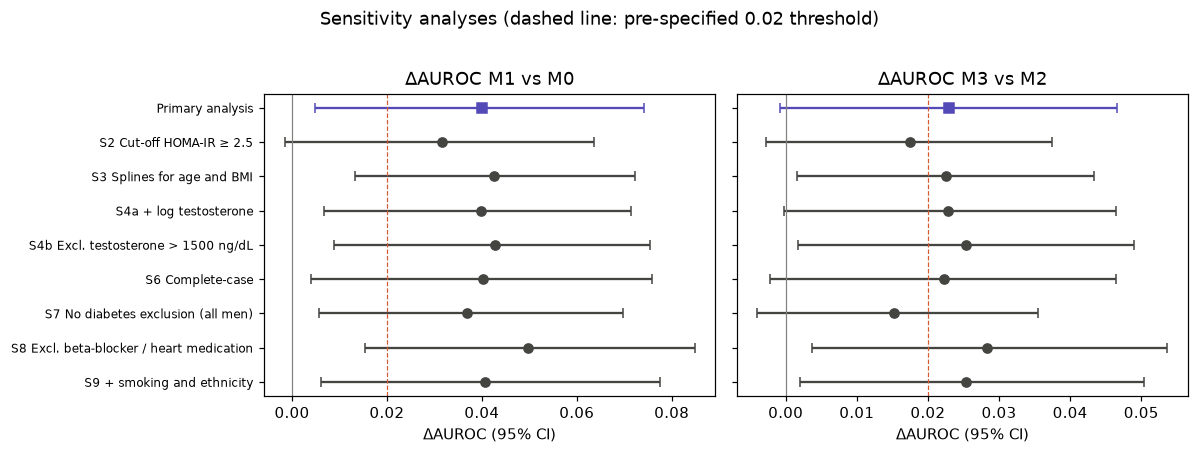

In [109]:
bin_checks = [s for s in SENS if s["kind"] == "logit" and not s["add_sd"]]
labels = ["Primary analysis"] + [s["name"] for s in bin_checks]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, lab in zip(axes, ["M1 vs M0", "M3 vs M2"]):
    vals = [PRIMARY["cons"][lab]] + [s["cons"][lab] for s in bin_checks]
    yy = np.arange(len(vals))[::-1]
    for k, (v, y_) in enumerate(zip(vals, yy)):
        ax.errorbar(v["Delta"], y_, xerr=[[v["Delta"] - v["lo"]], [v["hi"] - v["Delta"]]], fmt="s" if k == 0 else "o",
                    color="#534AB7" if k == 0 else "#444441", capsize=3)
    ax.axvline(0, color="grey", lw=0.8); ax.axvline(MIN_DAUROC, color="#D85A30", lw=0.8, ls="--")
    ax.set_title(f"ΔAUROC {lab}"); ax.set_xlabel("ΔAUROC (95% CI)")
axes[0].set_yticks(np.arange(len(labels))[::-1]); axes[0].set_yticklabels(labels, fontsize=8)
fig.suptitle("Sensitivity analyses (dashed line: pre-specified 0.02 threshold)", y=1.02)
fig.tight_layout(); save_fig(fig, "4.2_sensitivity_forest"); plt.show()

## 4.3 Interpret: which checks changed a conclusion, and in which direction

**How to read this.** The pre-specified rule flags *any* change, including changes that make the evidence stronger.
This table says, for every flagged check, exactly which criterion changed and whether the evidence became
stronger or weaker. Report the flagged count as specified, then use this table to explain it.

In [110]:
changes = []
for s in SENS:
    if s["add_sd"]:
        continue
    A = s["A"]
    top = A.loc[A["beta"].abs().idxmax(), "Feature"]
    if top != prim_top:
        changes.append({"Check": s["name"], "Criterion": "Top feature", "Change": f"{prim_top} -> {top}", "Direction": "different"})
    for i in range(len(A)):
        if np.sign(A["beta"].iloc[i]) != prim_sign[i]:
            changes.append({"Check": s["name"], "Criterion": "Association direction",
                            "Change": f"{A['Feature'].iloc[i]} flipped", "Direction": "weaker"})
    for lab, c in s["cons"].items():
        pc = PRIMARY["cons"][lab]
        if s["kind"] == "ols":
            if np.sign(c["Delta"]) != np.sign(pc["Delta"]):
                changes.append({"Check": s["name"], "Criterion": f"{lab} sign", "Change": "ΔR² sign differs from ΔAUROC", "Direction": "weaker"})
            if c["CI excludes 0"] != pc["CI excludes 0"]:
                changes.append({"Check": s["name"], "Criterion": f"{lab} CI",
                                "Change": "CI now " + ("excludes 0" if c["CI excludes 0"] else "includes 0"),
                                "Direction": "stronger" if c["CI excludes 0"] else "weaker"})
            continue
        if c["Δ ≥ 0.02"] != pc["Δ ≥ 0.02"]:
            changes.append({"Check": s["name"], "Criterion": f"{lab} size",
                            "Change": f"Δ {pc['Delta']:.3f} -> {c['Delta']:.3f} (" + ("now ≥ 0.02" if c["Δ ≥ 0.02"] else "now < 0.02") + ")",
                            "Direction": "stronger" if c["Δ ≥ 0.02"] else "weaker"})
        if c["CI excludes 0"] != pc["CI excludes 0"]:
            changes.append({"Check": s["name"], "Criterion": f"{lab} CI",
                            "Change": f"CI {pc['lo']:.3f} to {pc['hi']:.3f} -> {c['lo']:.3f} to {c['hi']:.3f} ("
                                      + ("now excludes 0" if c["CI excludes 0"] else "now includes 0") + ")",
                            "Direction": "stronger" if c["CI excludes 0"] else "weaker"})
changes = pd.DataFrame(changes, columns=["Check", "Criterion", "Change", "Direction"])
save_table(changes, "4.3_sensitivity_changes")
n_flag = (sens_tab["Conclusion unchanged"] == "No").sum(); n_eval = sens_tab["Conclusion unchanged"].isin(["Yes", "No"]).sum()
weaker = sorted(changes.loc[changes["Direction"] == "weaker", "Check"].unique())
stronger_only = sorted(set(changes["Check"]) - set(weaker))
print(f"Flagged by the pre-specified rule: {n_flag} of {n_eval} evaluable checks.")
print(f"  Evidence weaker in: {', '.join(weaker) if weaker else 'none'}")
print(f"  Evidence only stronger in: {', '.join(stronger_only) if stronger_only else 'none'}")
changes

Flagged by the pre-specified rule: 7 of 9 evaluable checks.
  Evidence weaker in: S2 Cut-off HOMA-IR ≥ 2.5, S7 No diabetes exclusion (all men)
  Evidence only stronger in: S1 Continuous log HOMA-IR, S3 Splines for age and BMI, S4b Excl. testosterone > 1500 ng/dL, S8 Excl. beta-blocker / heart medication, S9 + smoking and ethnicity


,Check,Criterion,Change,Direction
0,S1 Continuous log HOMA-IR,M3 vs M2 CI,CI now excludes 0,stronger
1,S2 Cut-off HOMA-IR ≥ 2.5,M1 vs M0 CI,CI 0.005 to 0.074 -> -0.002 to 0.064 (now includes 0),weaker
2,S2 Cut-off HOMA-IR ≥ 2.5,M3 vs M2 size,Δ 0.023 -> 0.017 (now < 0.02),weaker
3,S3 Splines for age and BMI,M3 vs M2 CI,CI -0.001 to 0.047 -> 0.002 to 0.043 (now excludes 0),stronger
4,S4b Excl. testosterone > 1500 ng/dL,M3 vs M2 CI,CI -0.001 to 0.047 -> 0.002 to 0.049 (now excludes 0),stronger
5,S7 No diabetes exclusion (all men),M3 vs M2 size,Δ 0.023 -> 0.015 (now < 0.02),weaker
6,S8 Excl. beta-blocker / heart medication,M3 vs M2 CI,CI -0.001 to 0.047 -> 0.004 to 0.054 (now excludes 0),stronger
7,S9 + smoking and ethnicity,M3 vs M2 CI,CI -0.001 to 0.047 -> 0.002 to 0.050 (now excludes 0),stronger


# Part 5: Summary for the write-up

Auto-generated from the numbers above, so it stays correct if you re-run the notebook. Wording is neutral on purpose:
interpretation belongs in your Discussion.

In [111]:
L = []
L.append(f"COHORT: {len(men)} men ({int(men['ir'].sum())} with HOMA-IR ≥ 2.9, {men['ir'].mean():.1%}) after excluding diabetes "
         f"(self-report, glucose-lowering medication, HbA1c ≥ 6.5% or fasting glucose ≥ 126 mg/dL).")
L.append("RQ1 (men), adjusted OR per SD [age + BMI]: " +
         "; ".join(f"{a} {b} (q={q})" for a, b, q in zip(rq1a["Feature"], rq1a["OR per SD, adjusted"], rq1a["q BH (adj.)"])))
L.append("RQ1 decision: " + RQ1_DECISION["Decision"] + ". Domains: " + RQ1_DECISION["Domain ranking by ΔAUROC over M0"])
lr = perf[perf["Model"] == MODEL_NAME["LR"]].set_index("Tier")
L.append("RQ2 (men, penalised LR) AUROC: " + "; ".join(f"{t} {lr.loc[t, 'AUROC (95% CI)']}" for t in TIERS))
for r_ in con[con["Model"] == MODEL_NAME["LR"]].itertuples():
    L.append(f"RQ2 {r_.Contrast} ({r_.Question}): ΔAUROC {fmt_ci(r_.Delta, r_.lo, r_.hi)}, "
             f"-> {r_.Conclusion}")
for mdl in ["XGB", "EBM"]:
    sub_ = con[con["Model"] == MODEL_NAME[mdl]]
    L.append(f"RQ2 secondary ({MODEL_NAME[mdl]}): " + "; ".join(f"{r_.Contrast} {fmt_ci(r_.Delta, r_.lo, r_.hi)}"
                                                               for r_ in sub_.itertuples()))
for r_ in RQ2_ANSWER.itertuples():
    L.append(f"RQ2 answer, {r_.Contrast} ({r_.Question}): LR test p = {r_[3]} (Holm {r_[9]}); ΔAUROC {r_[4]}; ΔAUPRC {r_[5]}; "
             f"ΔBrier {r_[6]}; P(ΔAUROC > 0) = {r_[7]}")
for t in SCREEN_T:
    r_ = scr_thr[(scr_thr["Refer if risk ≥"] == f"{t:.0%}")].set_index("Measure")
    n_ = scr_nb[scr_nb["Refer if risk ≥"] == f"{t:.0%}"].iloc[0]
    L.append(f"SCREENING, refer if risk ≥ {t:.0%} (M0 -> M1): referred per 100 {r_.loc['Referred per 100', 'Age + BMI (M0)']} -> "
             f"{r_.loc['Referred per 100', 'M0 + smartwatch (M1)']}; IR found per 100 {r_.loc['IR found per 100', 'Age + BMI (M0)']} -> "
             f"{r_.loc['IR found per 100', 'M0 + smartwatch (M1)']}; net tests avoided per 100 (M1 vs M0) {n_['Net tests avoided per 100, M1 vs M0']}")
for k in SCREEN_K:
    r_ = scr_cap[(scr_cap["Share referred"] == f"{k:.0%}")].set_index("Measure")
    L.append(f"SCREENING, refer top {k:.0%}: IR found per 100 {r_.loc['IR found per 100', 'Age + BMI (M0)']} -> "
             f"{r_.loc['IR found per 100', 'M0 + smartwatch (M1)']} (difference {r_.loc['IR found per 100', 'Difference, M1 - M0']})")
L.append(f"SENSITIVITY: conclusions unchanged in {(sens_tab['Conclusion unchanged'] == 'Yes').sum()} of {n_eval} evaluable checks; "
         f"flagged: {', '.join(sens_tab.loc[sens_tab['Conclusion unchanged'] == 'No', 'Check']) or 'none'}. "
         f"Evidence weaker in: {', '.join(weaker) if weaker else 'none'}; only stronger in: {', '.join(stronger_only) if stronger_only else 'none'}")
sd_row = sens_tab[sens_tab["Check"].str.startswith("S5")].iloc[0]
L.append(f"SENSITIVITY S5 (do day-to-day SDs add?): M1+SD vs M1 {sd_row['M1+SD vs M1']}; M3+SD vs M3 {sd_row['M3+SD vs M3']}")
summary_text = "\n\n".join(L)
(OUT_DIR / "5_results_summary.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)

COHORT: 464 men (108 with HOMA-IR ≥ 2.9, 23.3%) after excluding diabetes (self-report, glucose-lowering medication, HbA1c ≥ 6.5% or fasting glucose ≥ 126 mg/dL).

RQ1 (men), adjusted OR per SD [age + BMI]: Resting heart rate 1.90 (1.46 to 2.47) (q=7.6e-06); HRV 0.76 (0.58 to 1.00) (q=0.052); Daily steps 0.63 (0.49 to 0.81) (q=0.00087); Active zone minutes 0.78 (0.61 to 1.00) (q=0.052); Sleep duration 0.74 (0.59 to 0.94) (q=0.023)

RQ1 decision: 'Resting heart rate' is the strongest wearable feature (all three lenses agree, ≥50% of bootstraps). Domains: Cardiac (RHR + HRV) (+0.030) > Activity (steps + AZM) (+0.009) > Sleep (+0.004)

RQ2 (men, penalised LR) AUROC: M0 0.751 (0.700 to 0.801); M1 0.791 (0.743 to 0.838); M2 0.793 (0.744 to 0.839); M3 0.816 (0.770 to 0.861); M4 0.844 (0.805 to 0.880); M5 0.857 (0.820 to 0.894)

RQ2 M1 vs M0 (Beyond age + BMI): ΔAUROC 0.040 (0.005 to 0.074), -> Meaningful improvement (≥ 0.02, CI excludes 0)

RQ2 M3 vs M2 (Beyond routine blood panel): ΔAUROC 0.

## Session info

In [112]:
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "statsmodels": statsmodels.__version__, "xgboost": xgboost.__version__,
            "interpret": interpret.__version__, "matplotlib": matplotlib.__version__, "FAST_MODE": FAST_MODE,
            "seed": SEED, "cache": CACHE_KEY, "runtime_min": round((time.time() - T0) / 60, 1)}
pd.Series(versions).to_frame("value").to_csv(OUT_DIR / "session_info.csv")
print(pd.Series(versions).to_string())

python                                                      3.12.15
numpy                                                         2.5.3
pandas                                                        3.0.6
scikit-learn                                                  1.9.1
statsmodels                                                  0.15.0
xgboost                                                       3.4.1
interpret                                                     0.7.8
matplotlib                                                   3.11.2
FAST_MODE                                                     False
seed                                                       20260922
cache           full_r20-10_b2000-1000_s100_seed20260922_3e3e46df22
runtime_min                                                     1.8
